In [1]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append('../src')

import os
os.environ["POLARS_MAX_THREADS"] = '16'

from pathlib import Path
import numpy as np
import polars as pl
from tqdm.notebook import tqdm
from matplotlib import pyplot as plt
from joblib import load

from light_curves import read_fits_lc, preprocess_lc, PreprocessingConfig
from periodogram_features import compute_periodogram

plt.style.use("tess_journal.mplstyle")

cfg = PreprocessingConfig()
training_set = 'training_set_v13'
df_training_set = pl.read_parquet(Path('../data') / f"{training_set}.parquet").select(['path', 'label', 'GaiaID', 'sector']).rename({'GaiaID': 'GaiaDR3'})

model_path = Path('../results/classifications') / f"{training_set}_reg"
le = load(model_path / 'label_encoder.pkl')

# Main summaries

In [2]:
df_all_preds = pl.scan_parquet(
    '../results/classifications/s*/*.parquet',  # Contains GaiaDR3 and sector
).join(
    pl.scan_parquet('../results/features/s*/*.parquet').select(
        ['path', 'ls_frequency_dominant', 'ls_amplitude_dominant', 'flux_std', 'lc_num_negative_fluxes', 'lc_num_obs_after_preprocessing', 
         'pw_variance_explained_1', 'pw_frequency_2', 'pw_variance_explained_2']
    ).filter(
        pl.col('lc_num_negative_fluxes').eq(0) & pl.col('lc_num_obs_after_preprocessing').gt(500)
    ).drop(['lc_num_negative_fluxes', 'lc_num_obs_after_preprocessing']),
    on='path'
).collect()
df_all_preds

path,CONTACT_ROT,DSCT_BCEP,ECLIPSE,GDOR_SPB,INSTRUMENTAL,RRLYR_CEPH,SOLARLIKE,best_class,entropy,best_proba,sector,GaiaDR3,ls_frequency_dominant,ls_amplitude_dominant,flux_std,pw_variance_explained_1,pw_frequency_2,pw_variance_explained_2
str,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,i64,i64,f64,f64,f64,f64,f64,f64
"""/STER/mamsie/tess/TIC/plato_fo…",0.00012,0.000032,0.024342,0.000041,0.975465,5.0321e-7,1.8019e-7,"""INSTRUMENTAL""",0.059873,0.975465,1,4674485969374108672,0.998792,0.16142,0.014619,0.324507,0.933404,0.125359
"""/STER/mamsie/tess/TIC/plato_fo…",0.000152,0.000026,0.007348,0.00003,0.992443,3.0487e-7,4.0208e-7,"""INSTRUMENTAL""",0.023419,0.992443,1,4674480643614643456,0.998792,0.160733,0.014168,0.308535,0.932685,0.128418
"""/STER/mamsie/tess/TIC/plato_fo…",0.000426,0.00005,0.002191,0.000027,0.99726,0.000011,0.000035,"""INSTRUMENTAL""",0.010648,0.99726,1,4674487653001305088,0.941308,0.113188,0.0589,0.132421,1.003104,0.142739
"""/STER/mamsie/tess/TIC/plato_fo…",0.00025,0.000014,0.118488,0.000114,0.881129,0.000003,5.3813e-7,"""INSTRUMENTAL""",0.188886,0.881129,1,4674481262089950592,0.998074,0.154457,0.157018,0.250343,0.931248,0.134494
"""/STER/mamsie/tess/TIC/plato_fo…",0.000121,0.000007,0.007926,0.00003,0.991914,3.0598e-7,1.1121e-7,"""INSTRUMENTAL""",0.024616,0.991914,1,4674486244252033024,0.999511,0.186314,0.008692,0.341004,0.934122,0.125661
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""/STER/mamsie/tess/TIC/plato_fo…",0.000693,0.000012,0.000002,0.000185,0.98049,9.2015e-7,0.018617,"""INSTRUMENTAL""",0.051541,0.98049,39,5500168796098016512,1.00368,0.051825,0.019721,0.06796,1.199119,0.024676
"""/STER/mamsie/tess/TIC/plato_fo…",0.169095,0.000035,0.000039,0.023707,0.786238,0.000005,0.020881,"""INSTRUMENTAL""",0.339137,0.786238,39,5500164569850212096,1.196255,0.088783,0.022813,0.099592,0.942829,0.02309
"""/STER/mamsie/tess/TIC/plato_fo…",0.027755,0.000022,0.000077,0.000528,0.958864,9.2000e-7,0.012753,"""INSTRUMENTAL""",0.10296,0.958864,39,5500161340034711424,0.942113,0.065089,0.03019,0.08953,0.997953,0.045086


In [3]:
# Histogram of best class

df_all_preds.group_by('best_class').len().sort('best_class').with_columns((100*pl.col('len')/pl.col('len').sum()).alias('percent'))

best_class,len,percent
str,u32,f64
"""CONTACT_ROT""",1603829,4.382511
"""DSCT_BCEP""",665201,1.817682
"""ECLIPSE""",405207,1.10724
"""GDOR_SPB""",281848,0.770158
"""INSTRUMENTAL""",33056511,90.327907
"""RRLYR_CEPH""",48931,0.133705
"""SOLARLIKE""",534595,1.460797


[Text(0, 0, '0'),
 Text(-1, 0, '0.9'),
 Text(-2, 0, '0.99'),
 Text(-3, 0, '0.999'),
 Text(-4, 0, '0.9999'),
 Text(-5, 0, '0.99999')]

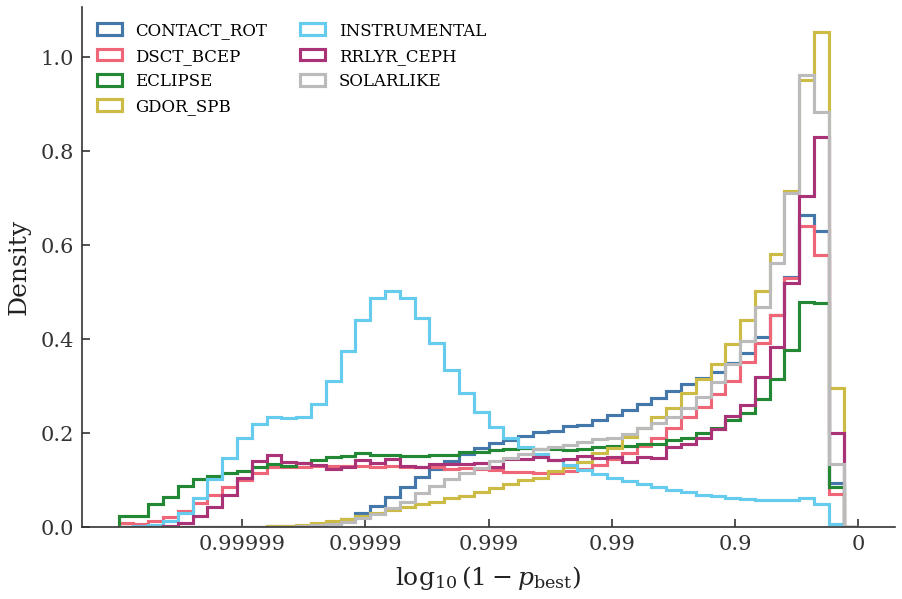

In [4]:
best_class = df_all_preds['best_class'].to_numpy()
best_proba, entropy = df_all_preds[['best_proba', 'entropy']].to_numpy().T

fig, ax = plt.subplots(figsize=(7, 4.5))

for cls in le.classes_:
    mask = best_class == cls
    p = best_proba[mask]
    p = np.clip(p, 1e-6, 1 - 1e-6)
    log_miss = np.log10(1 - p)
    ax.hist(log_miss, bins=50, range=(-6, 0), density=True, histtype="step", linewidth=1.5, label=cls)

ax.set_xlabel(r"$\log_{10}(1 - p_{\mathrm{best}})$")
ax.set_ylabel("Density")
ax.legend(fontsize=8, ncol=2)
tick_positions = [0, -1, -2, -3, -4, -5]
tick_labels = ["0", "0.9", "0.99", "0.999", "0.9999", "0.99999"]

ax.set_xticks(tick_positions)
ax.set_xticklabels(tick_labels)

## A few examples per class

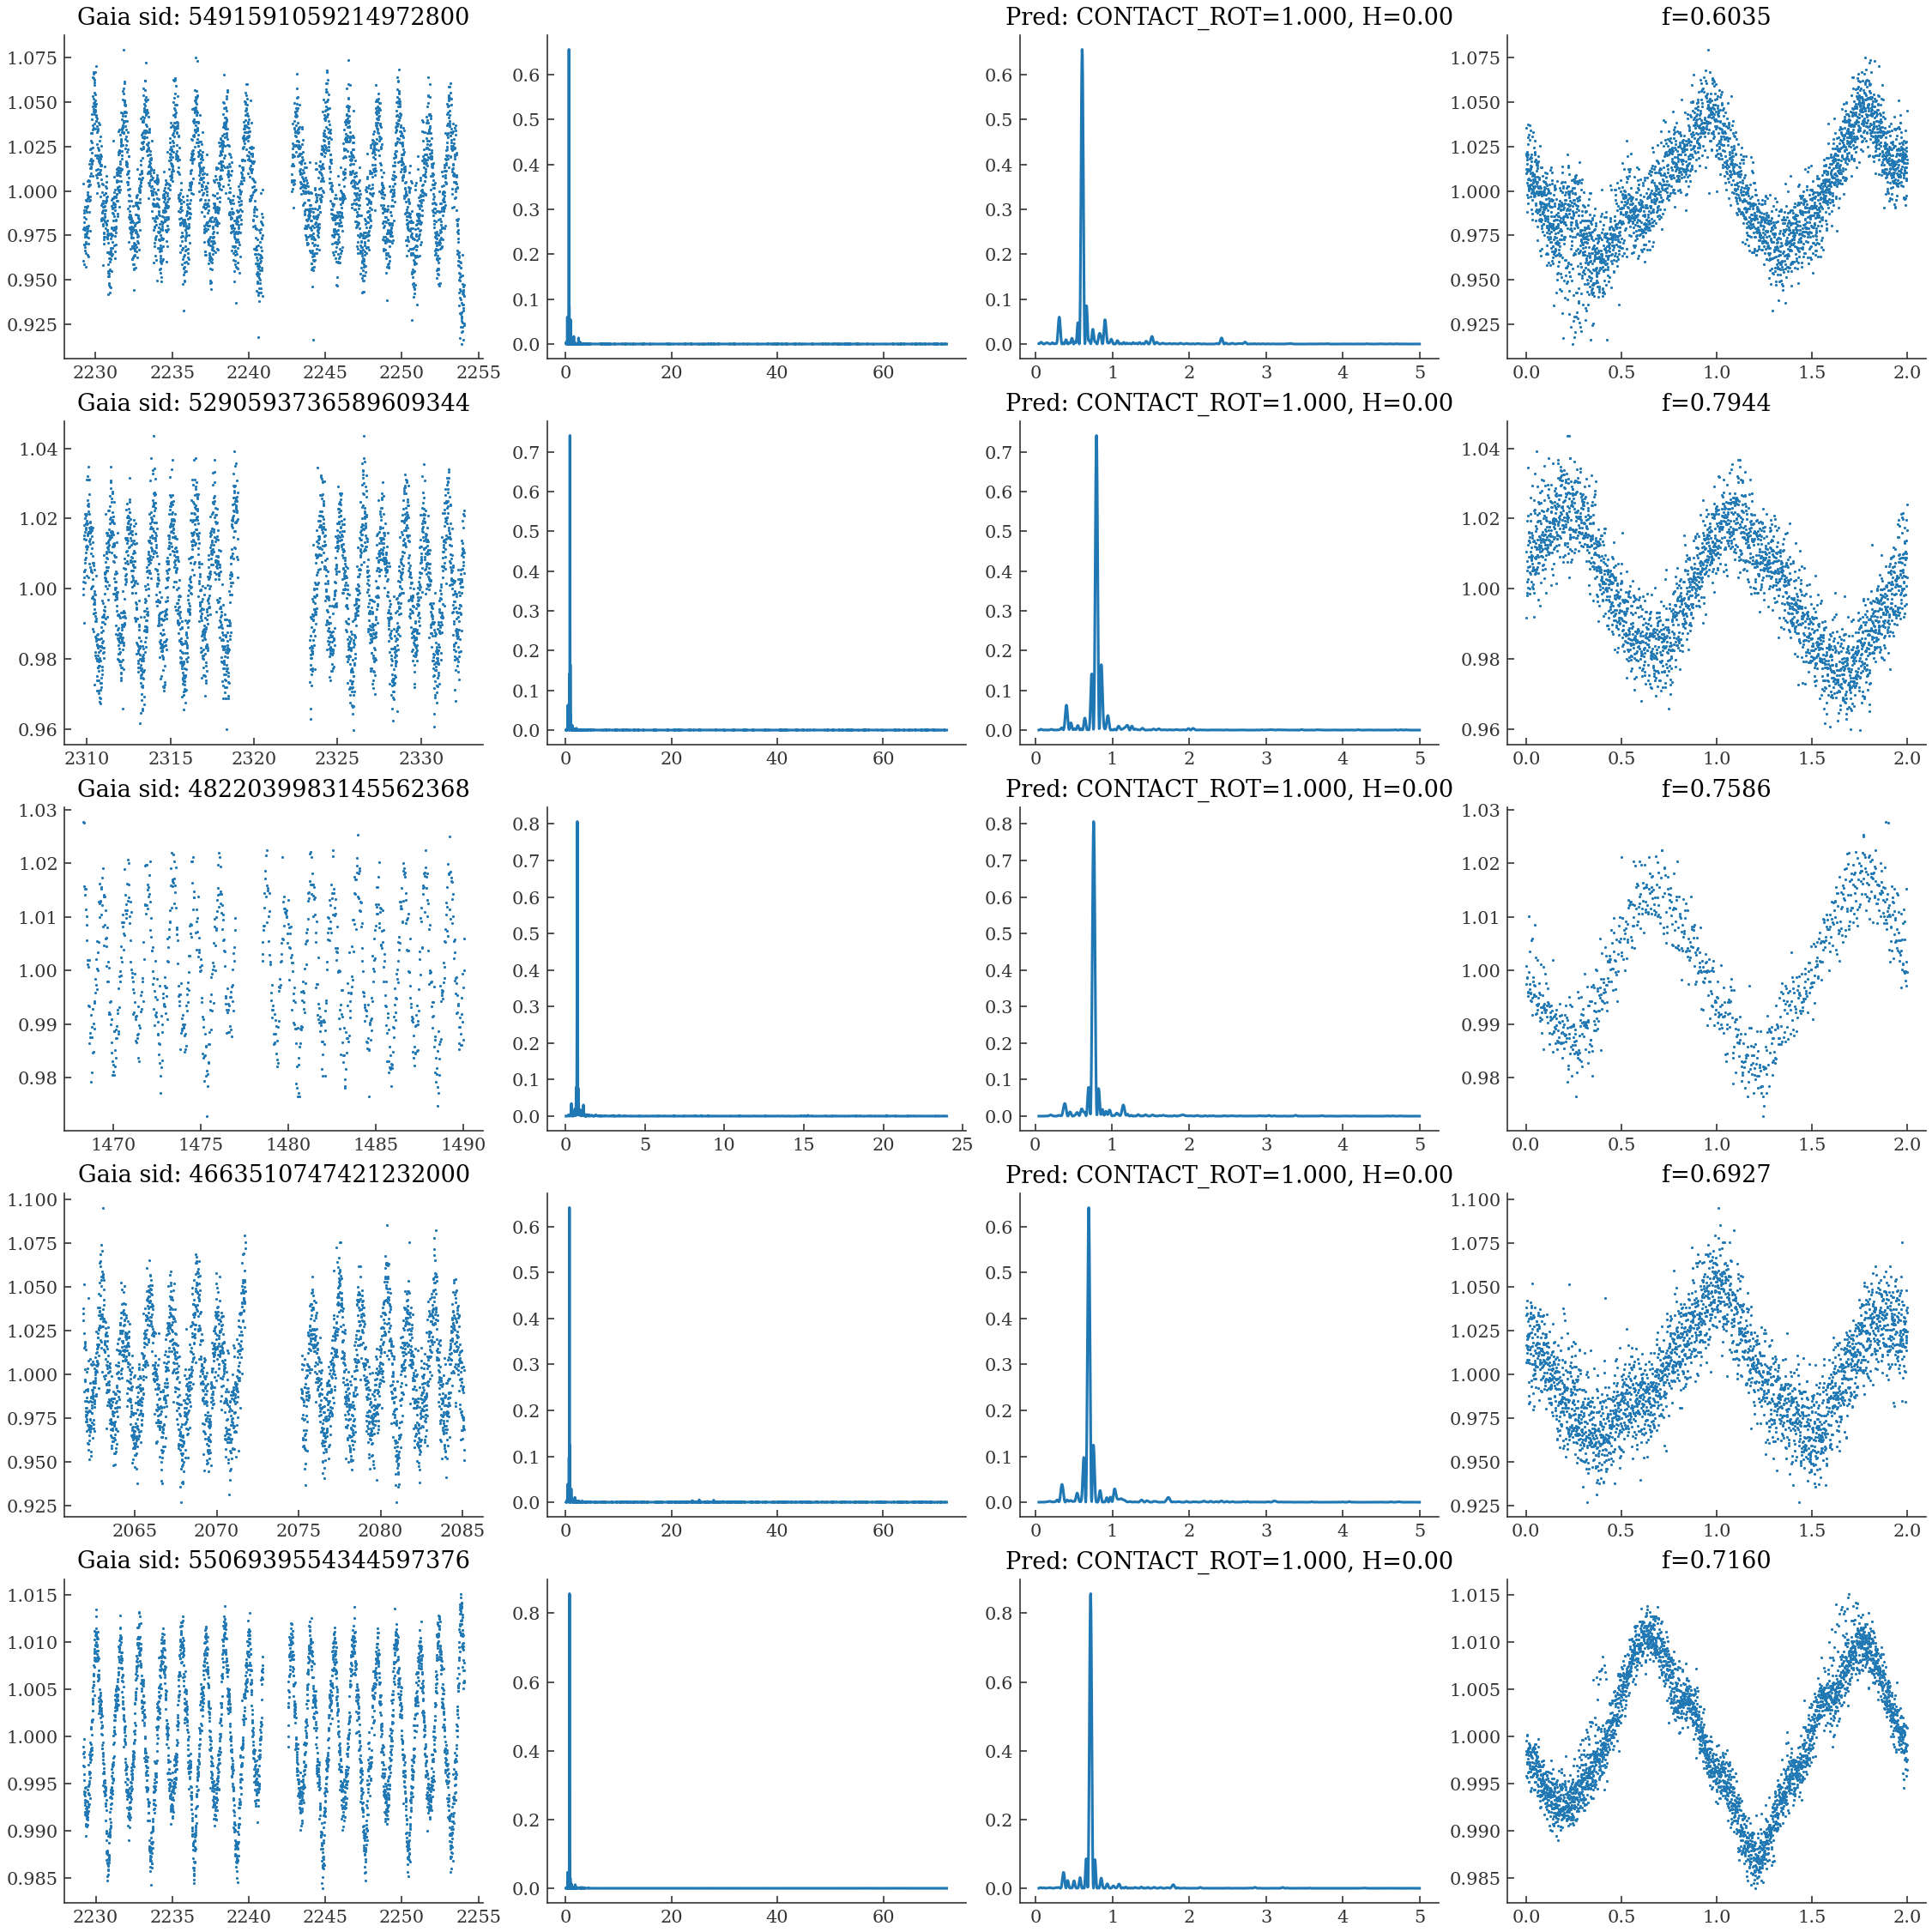

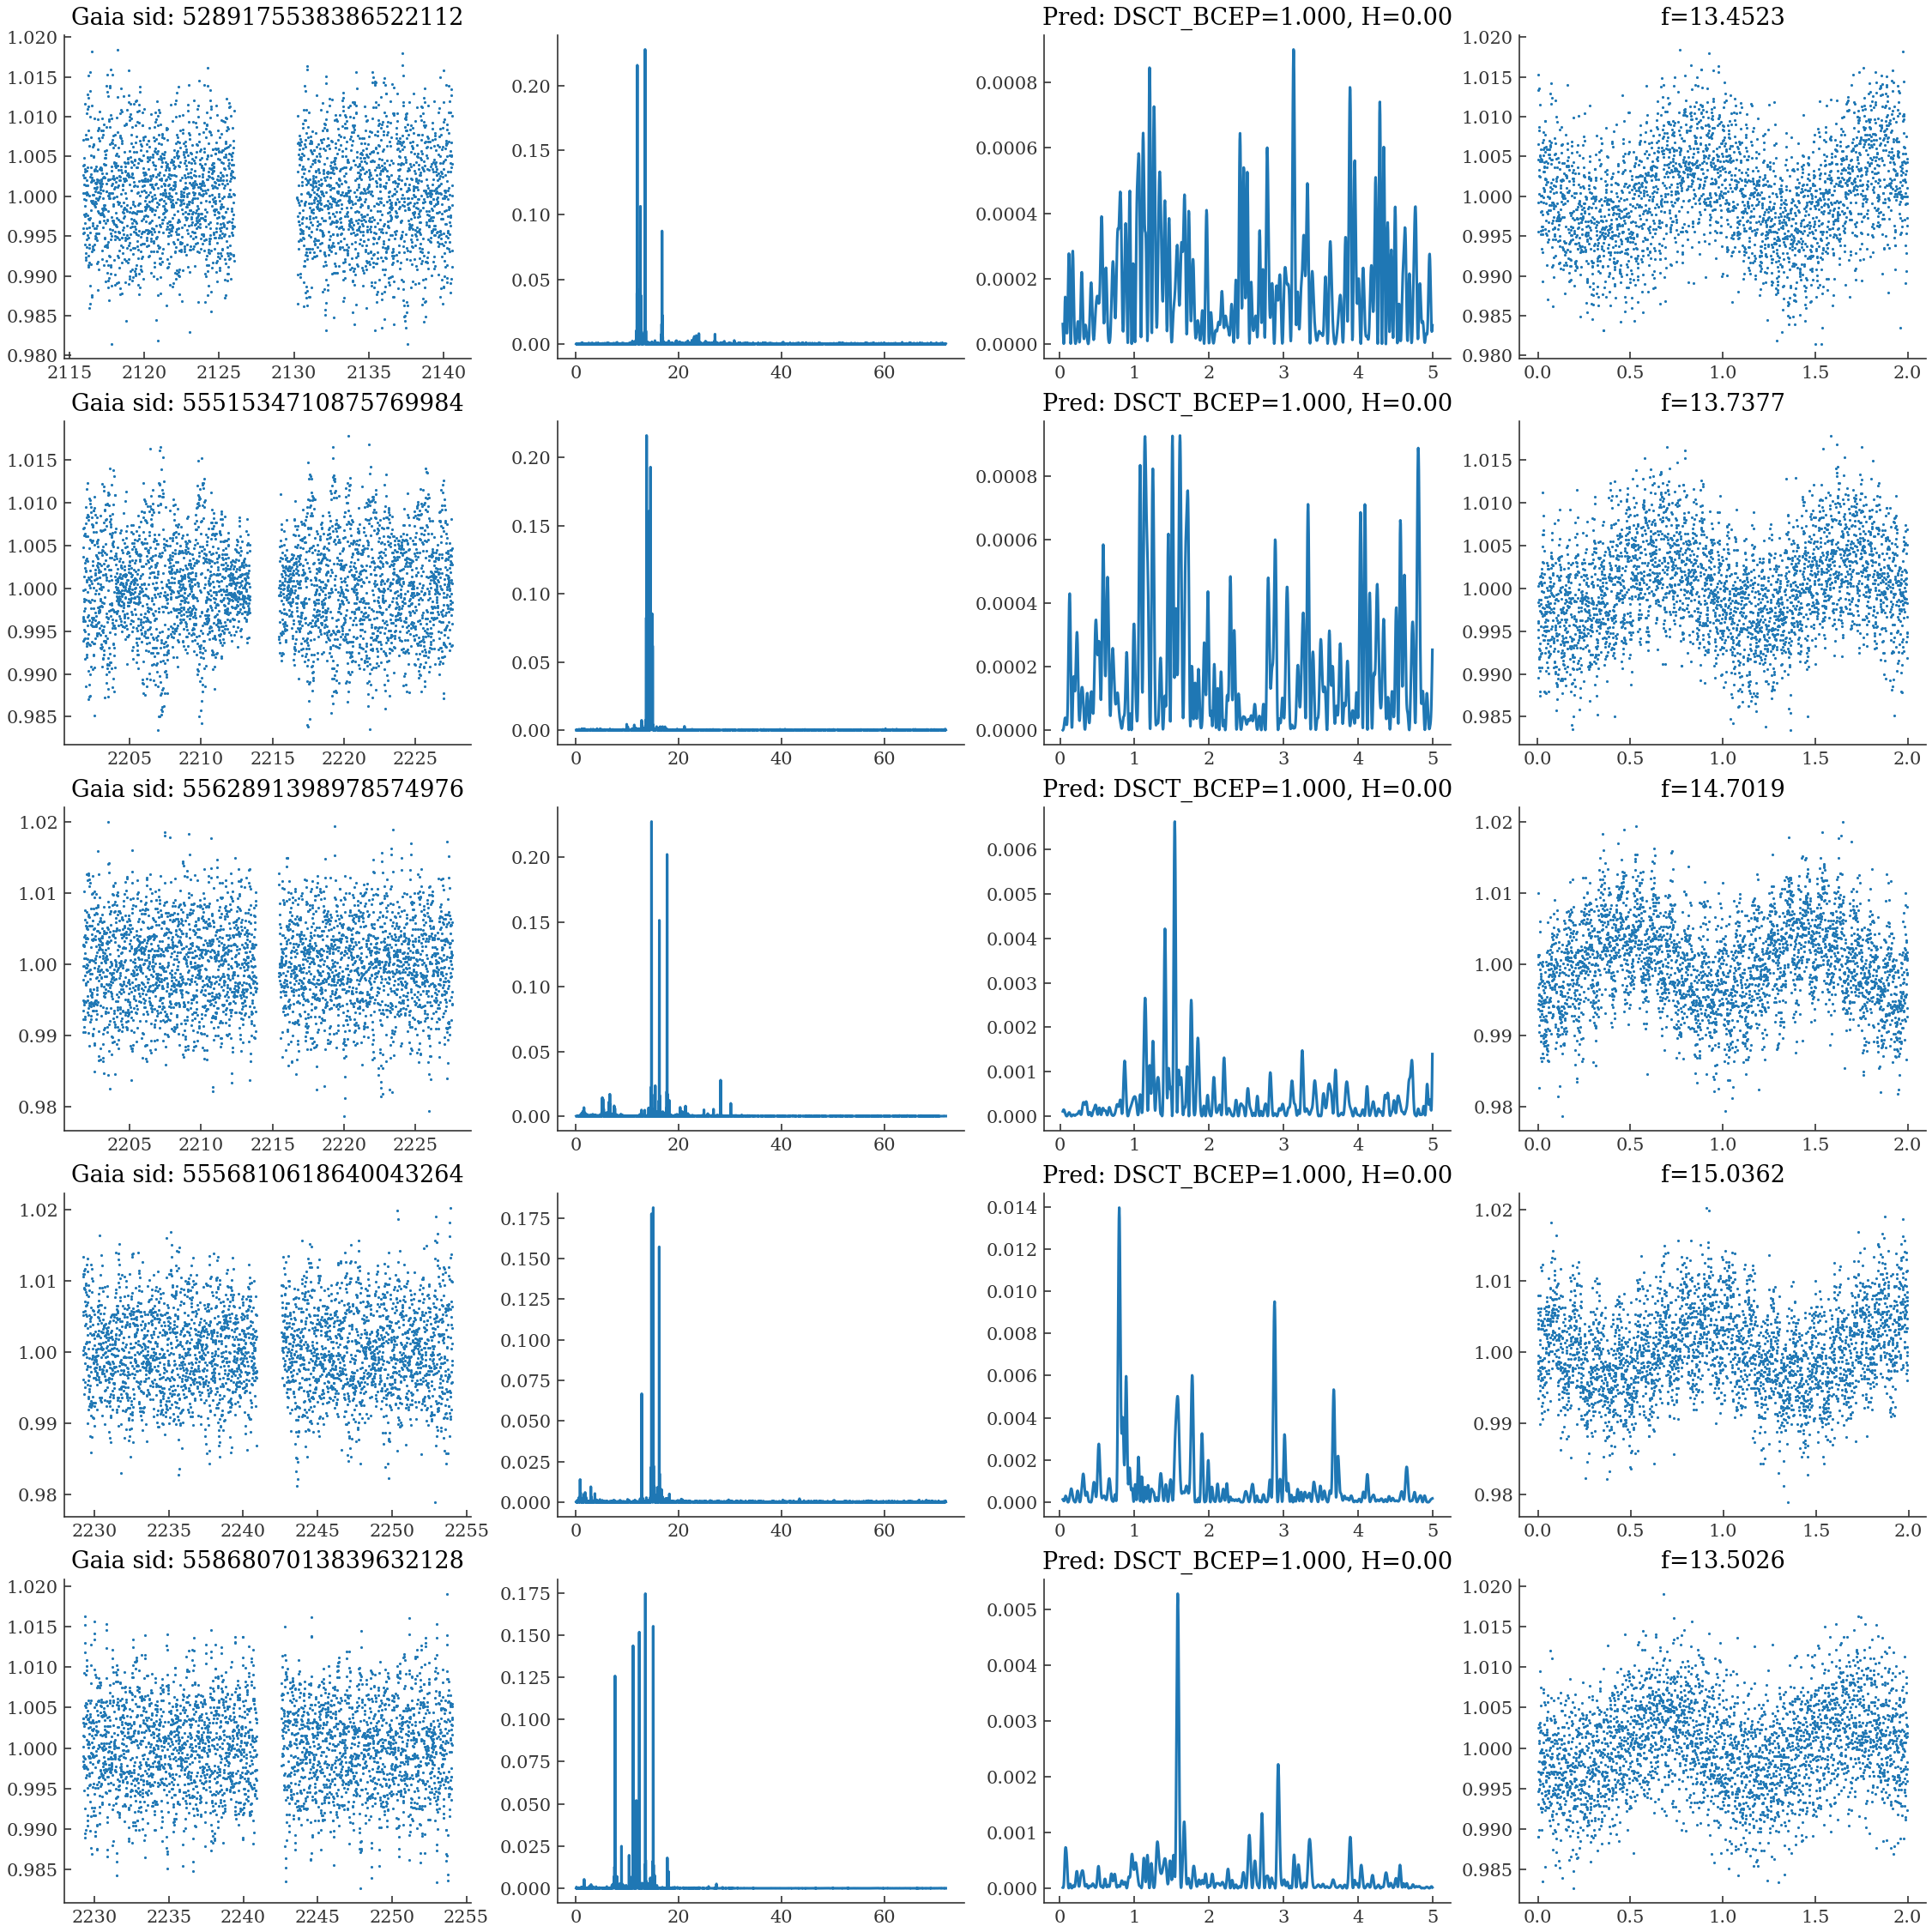

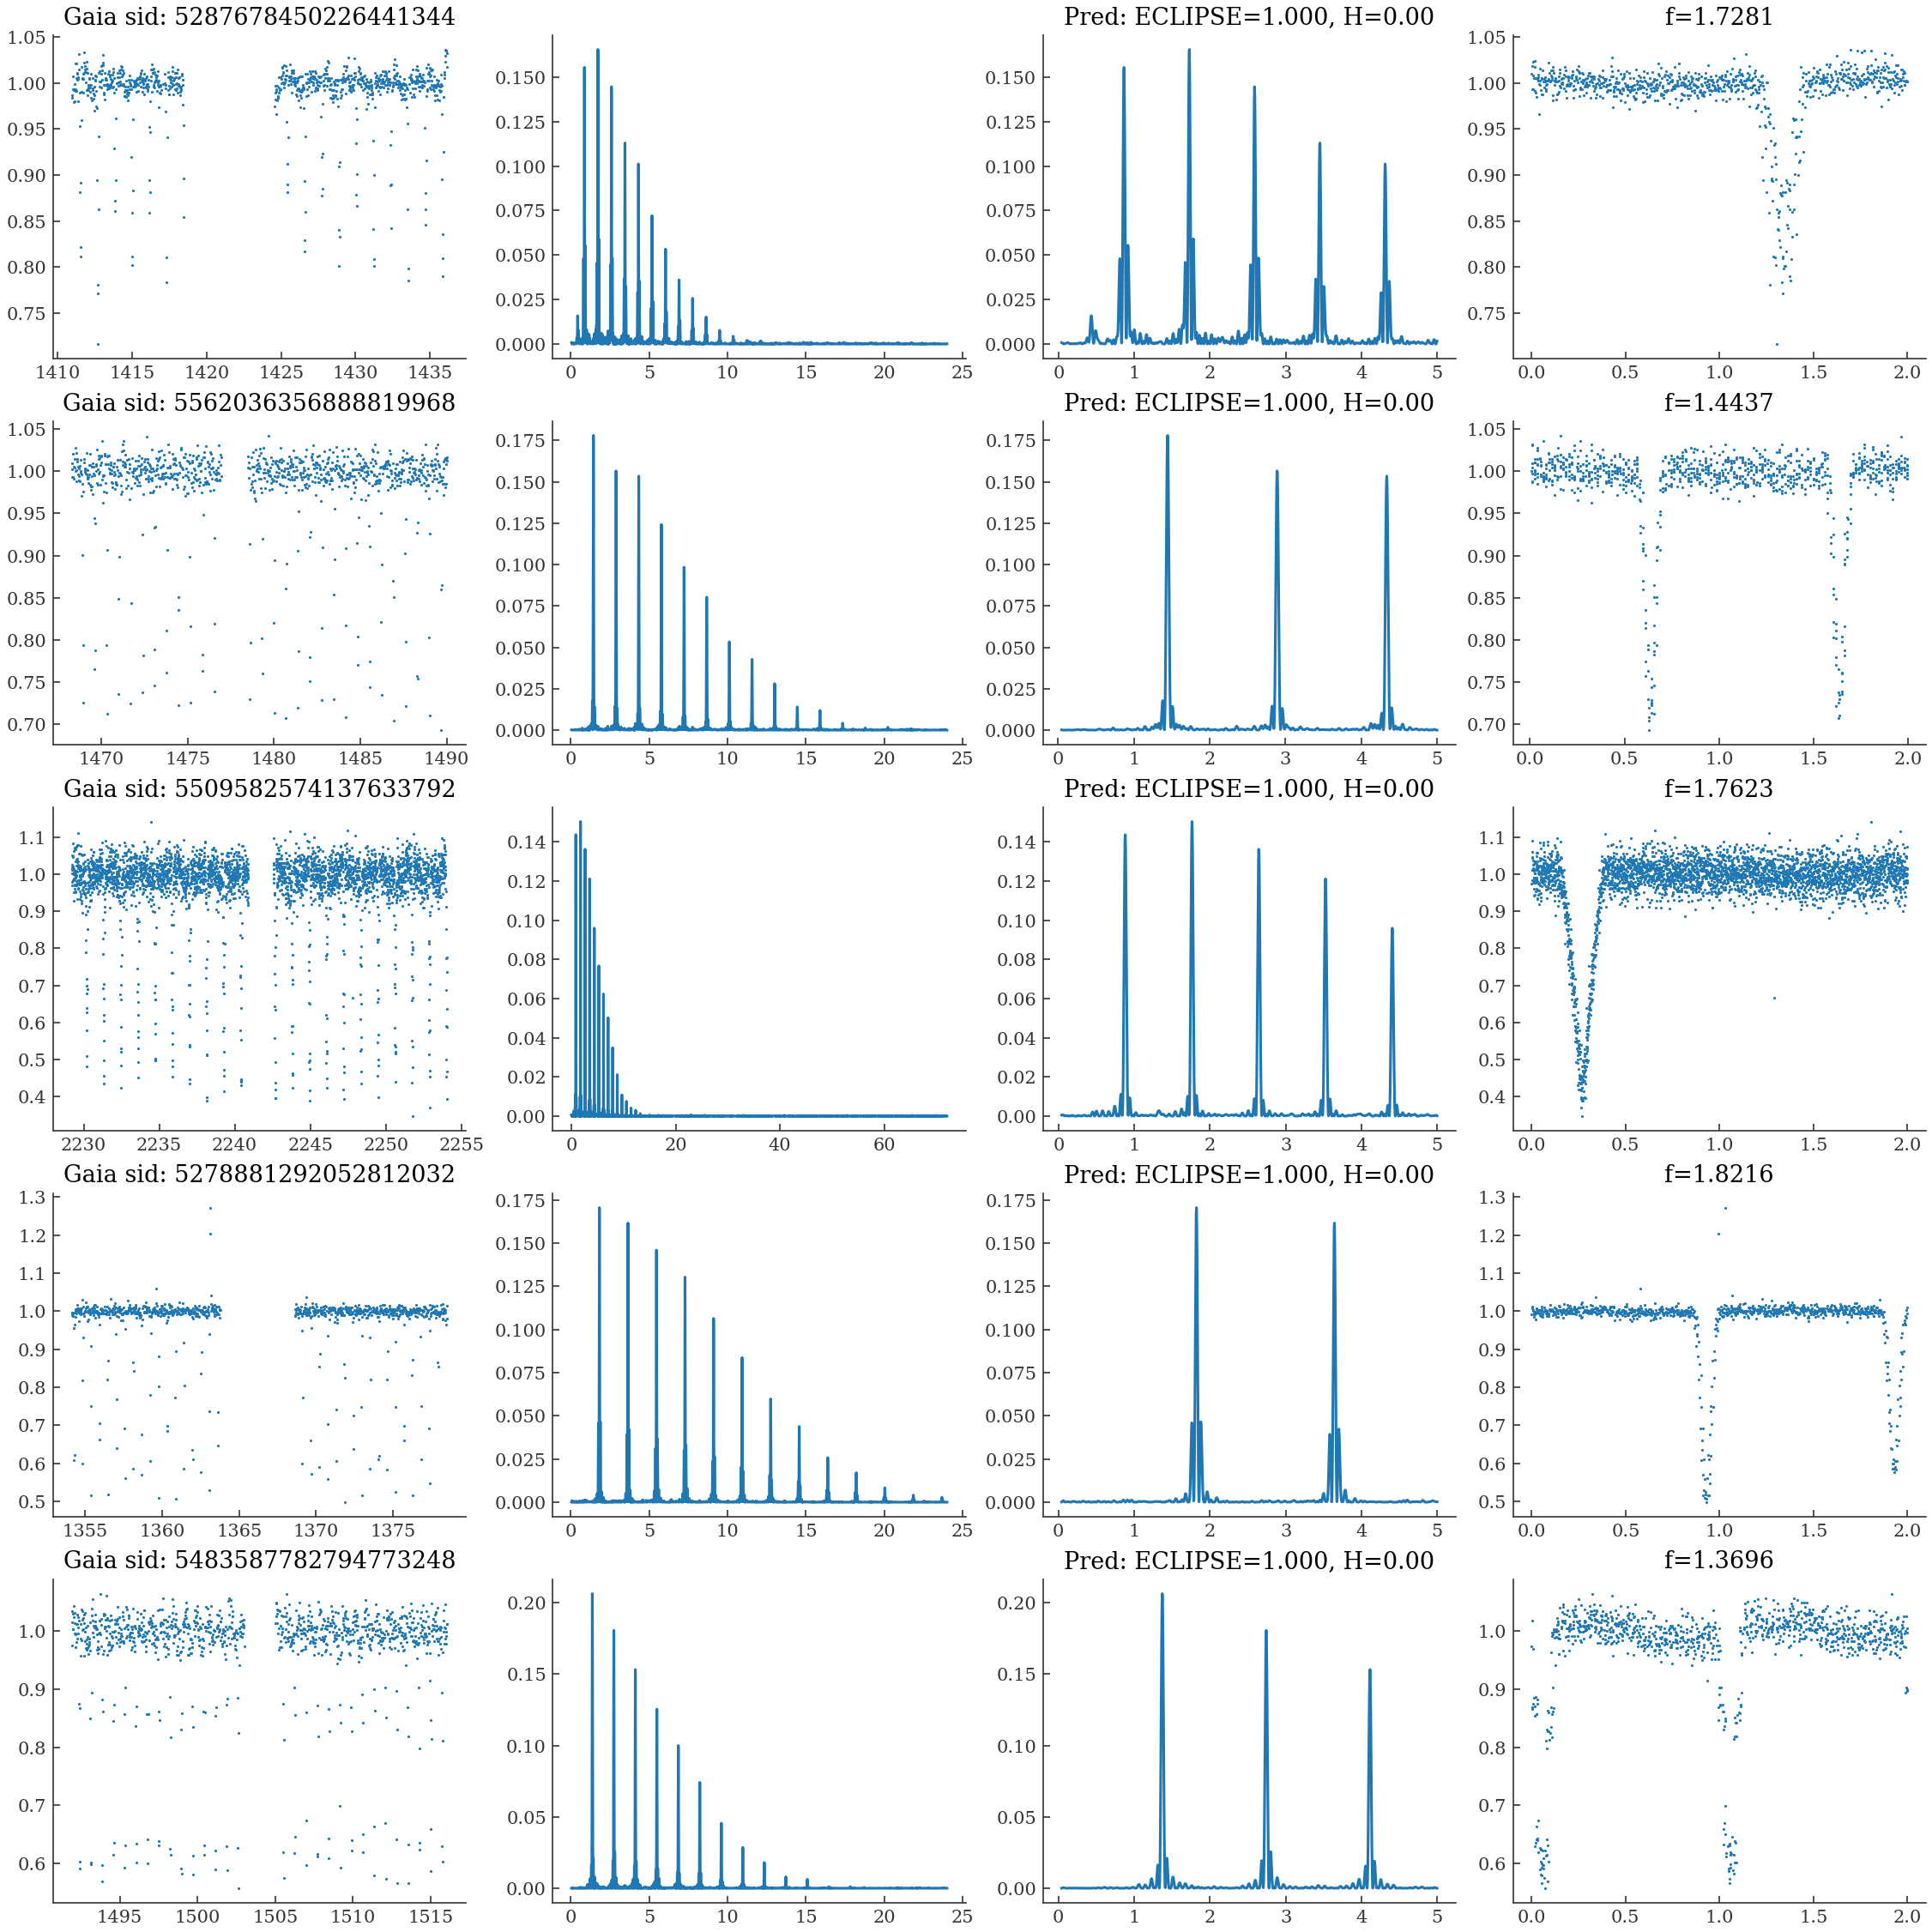

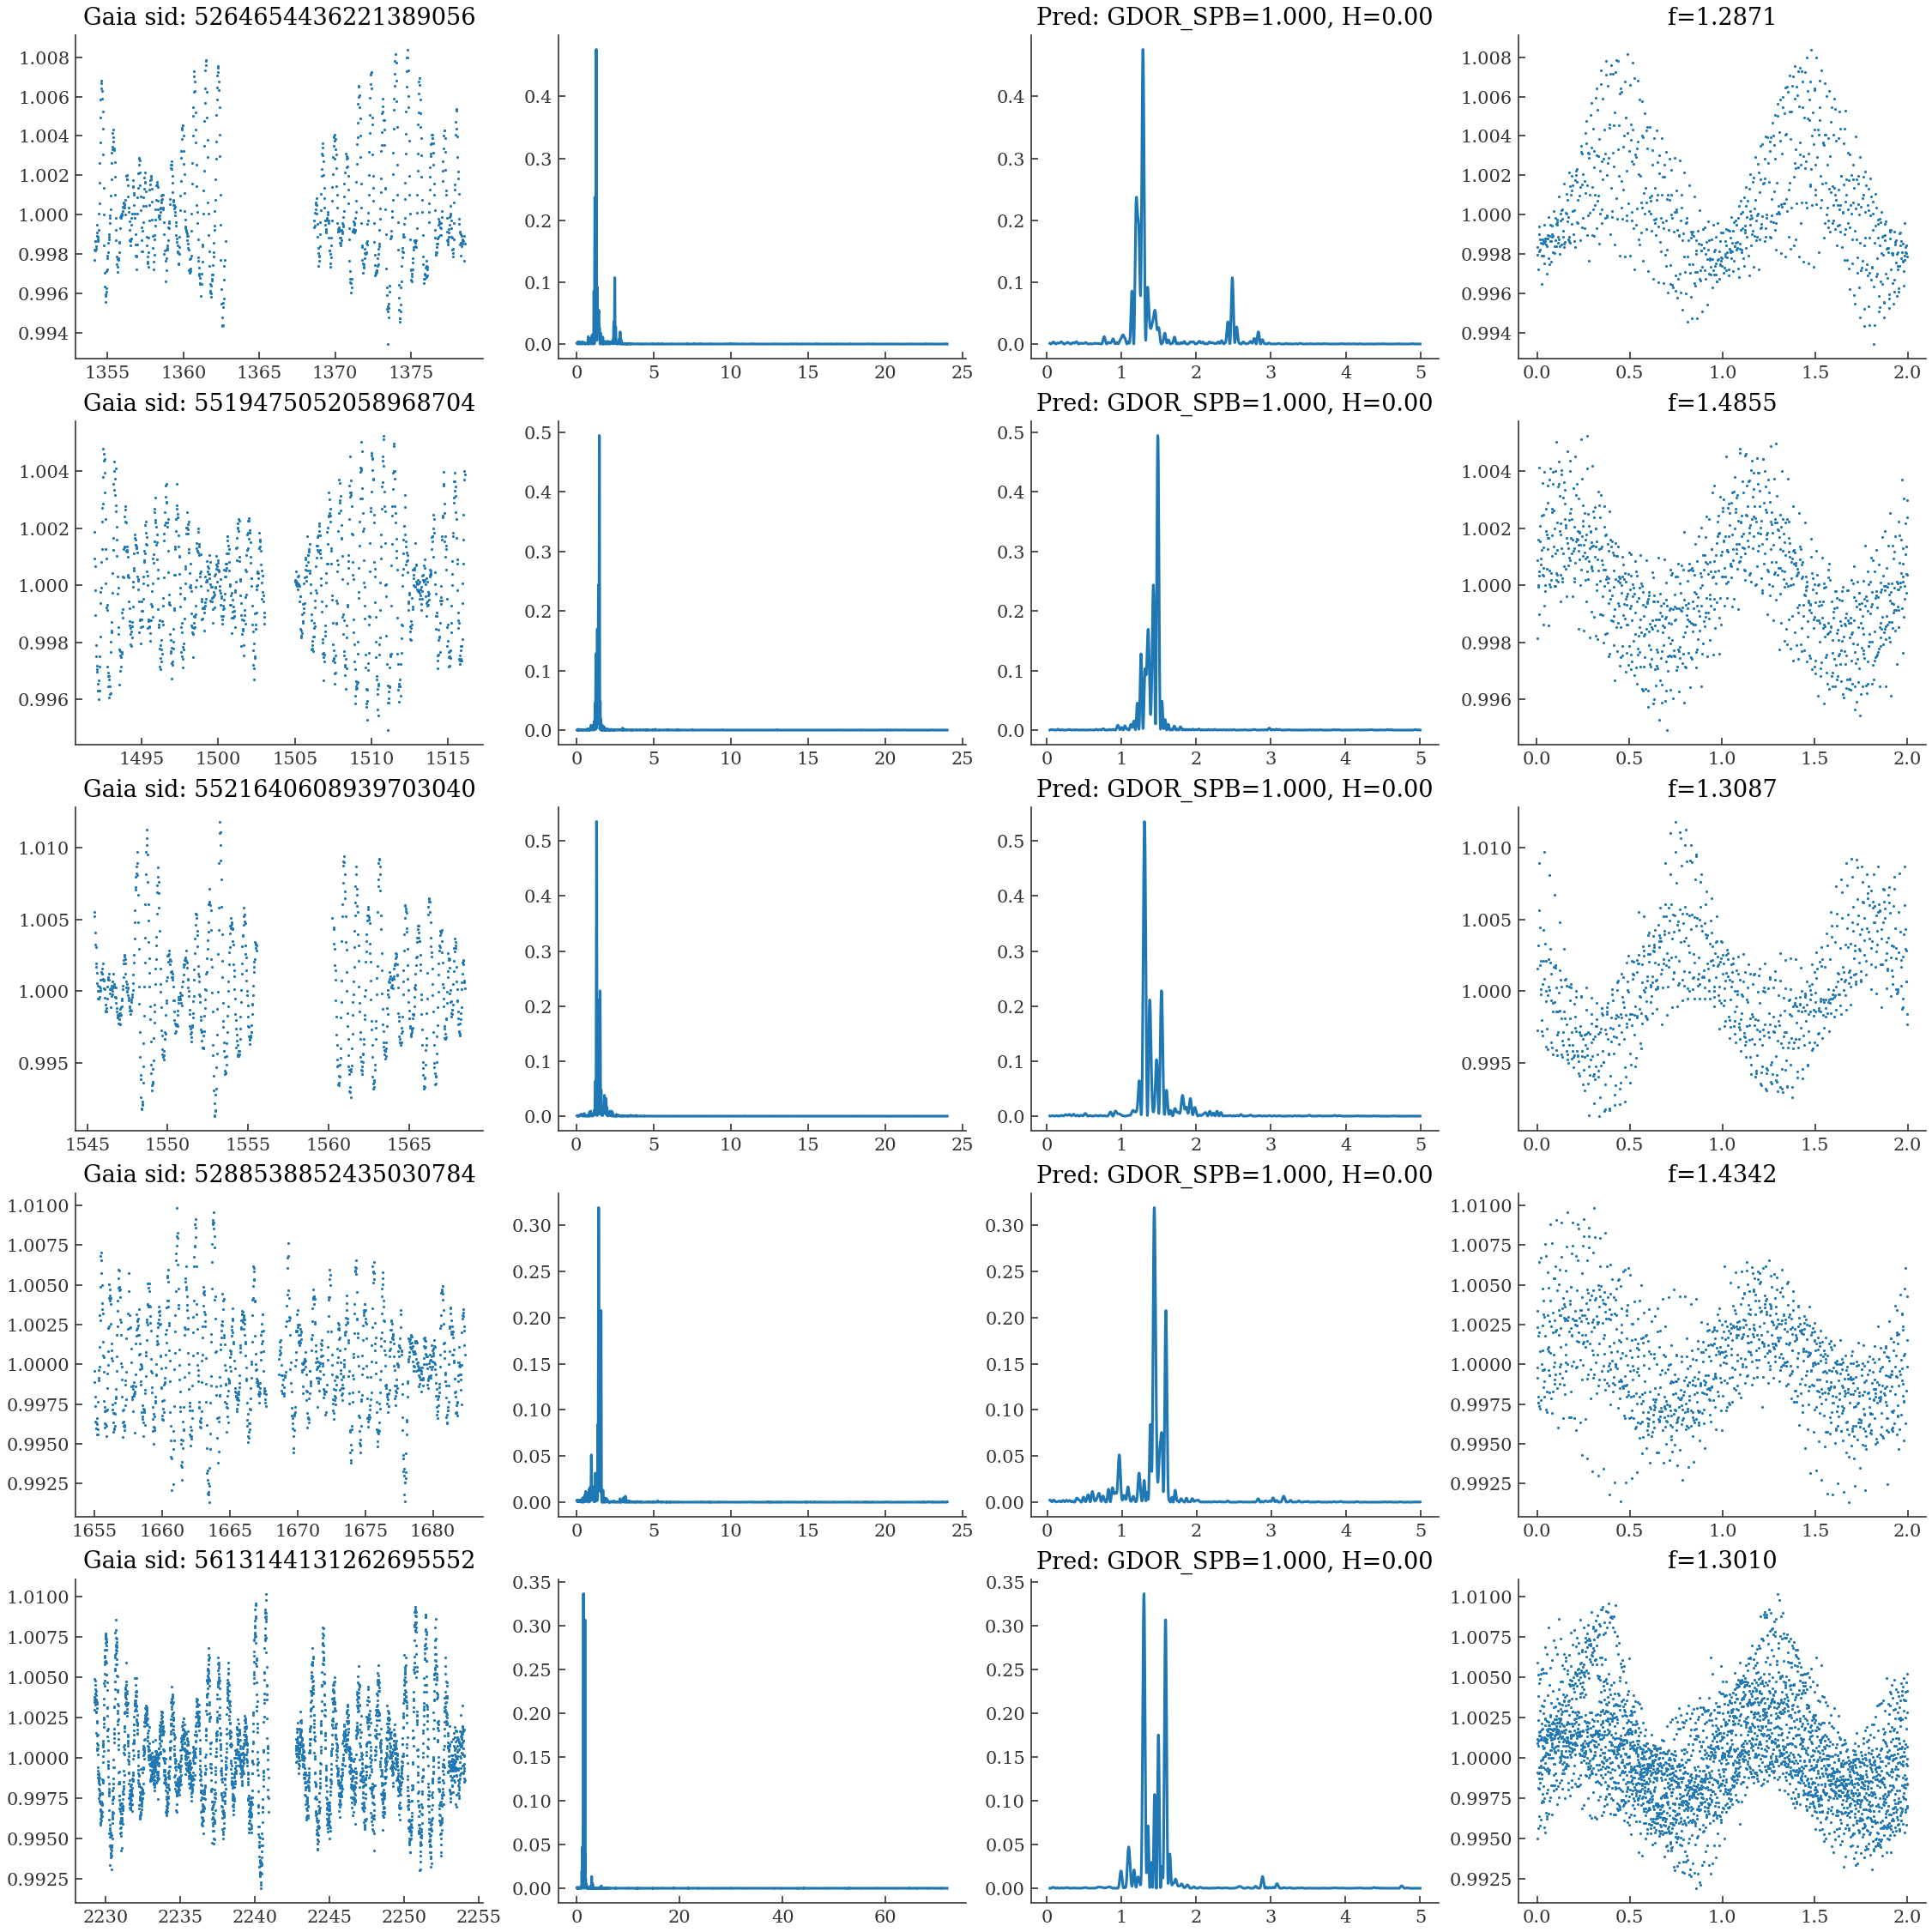

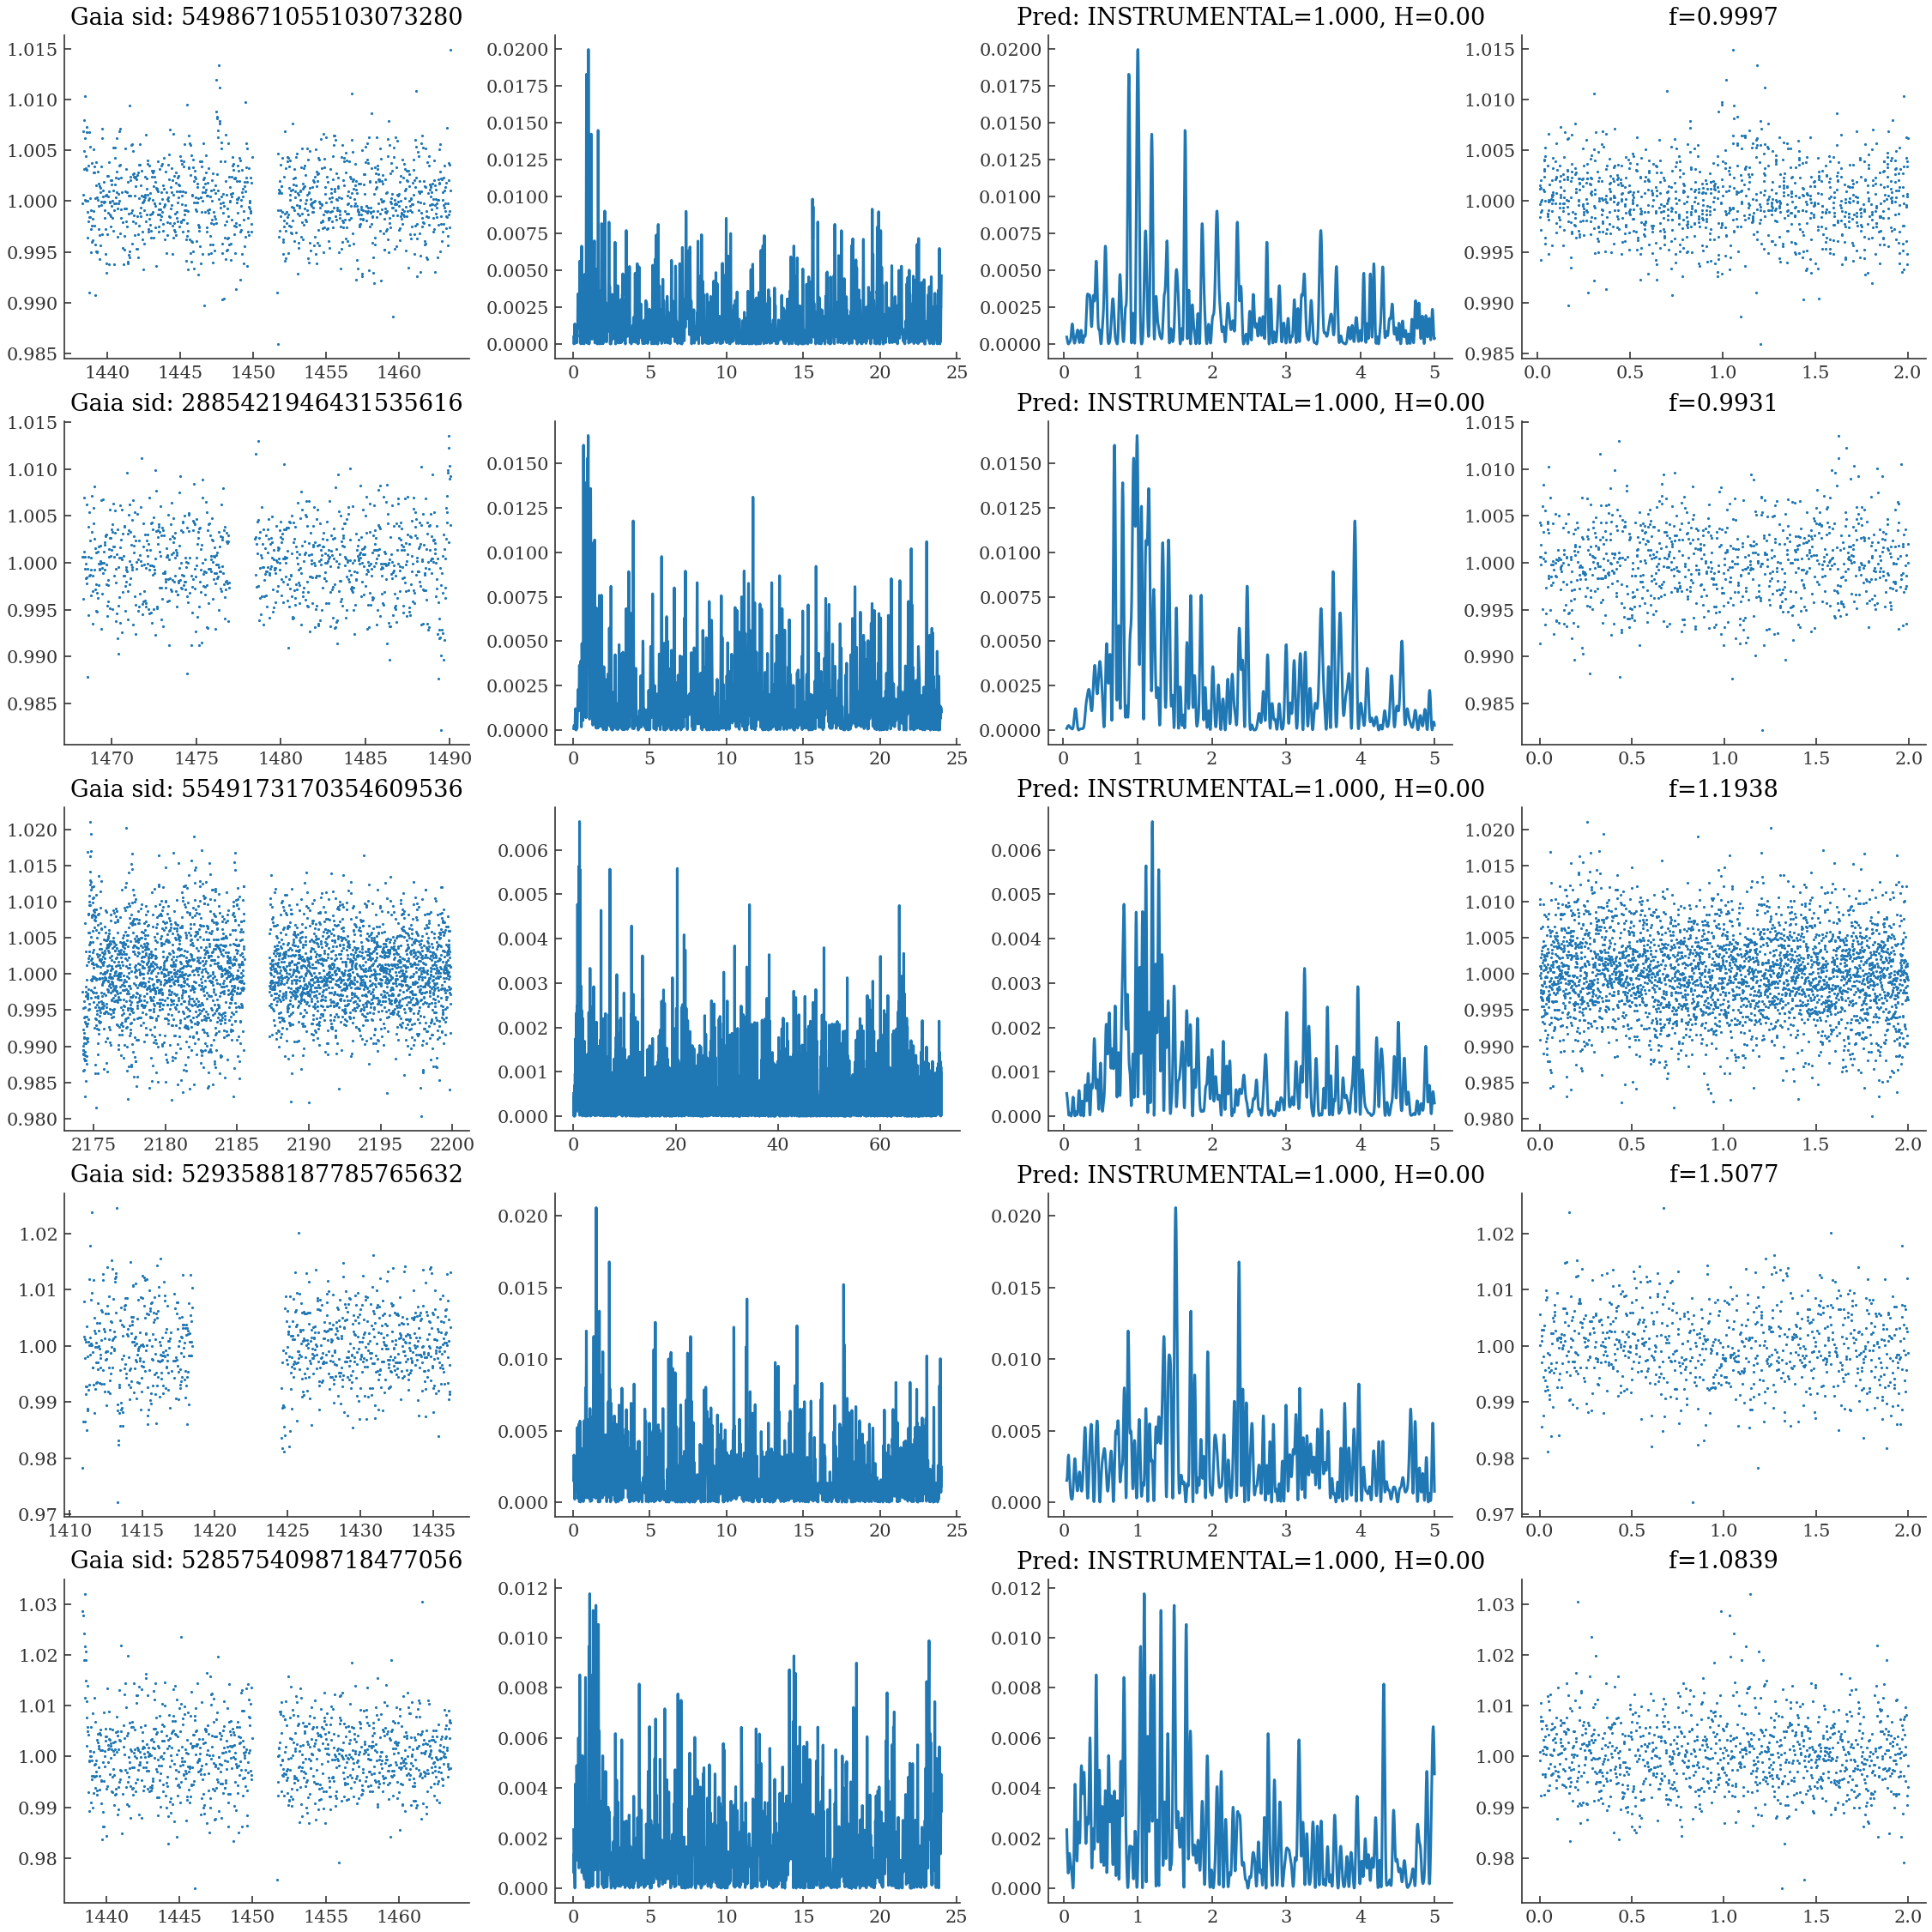

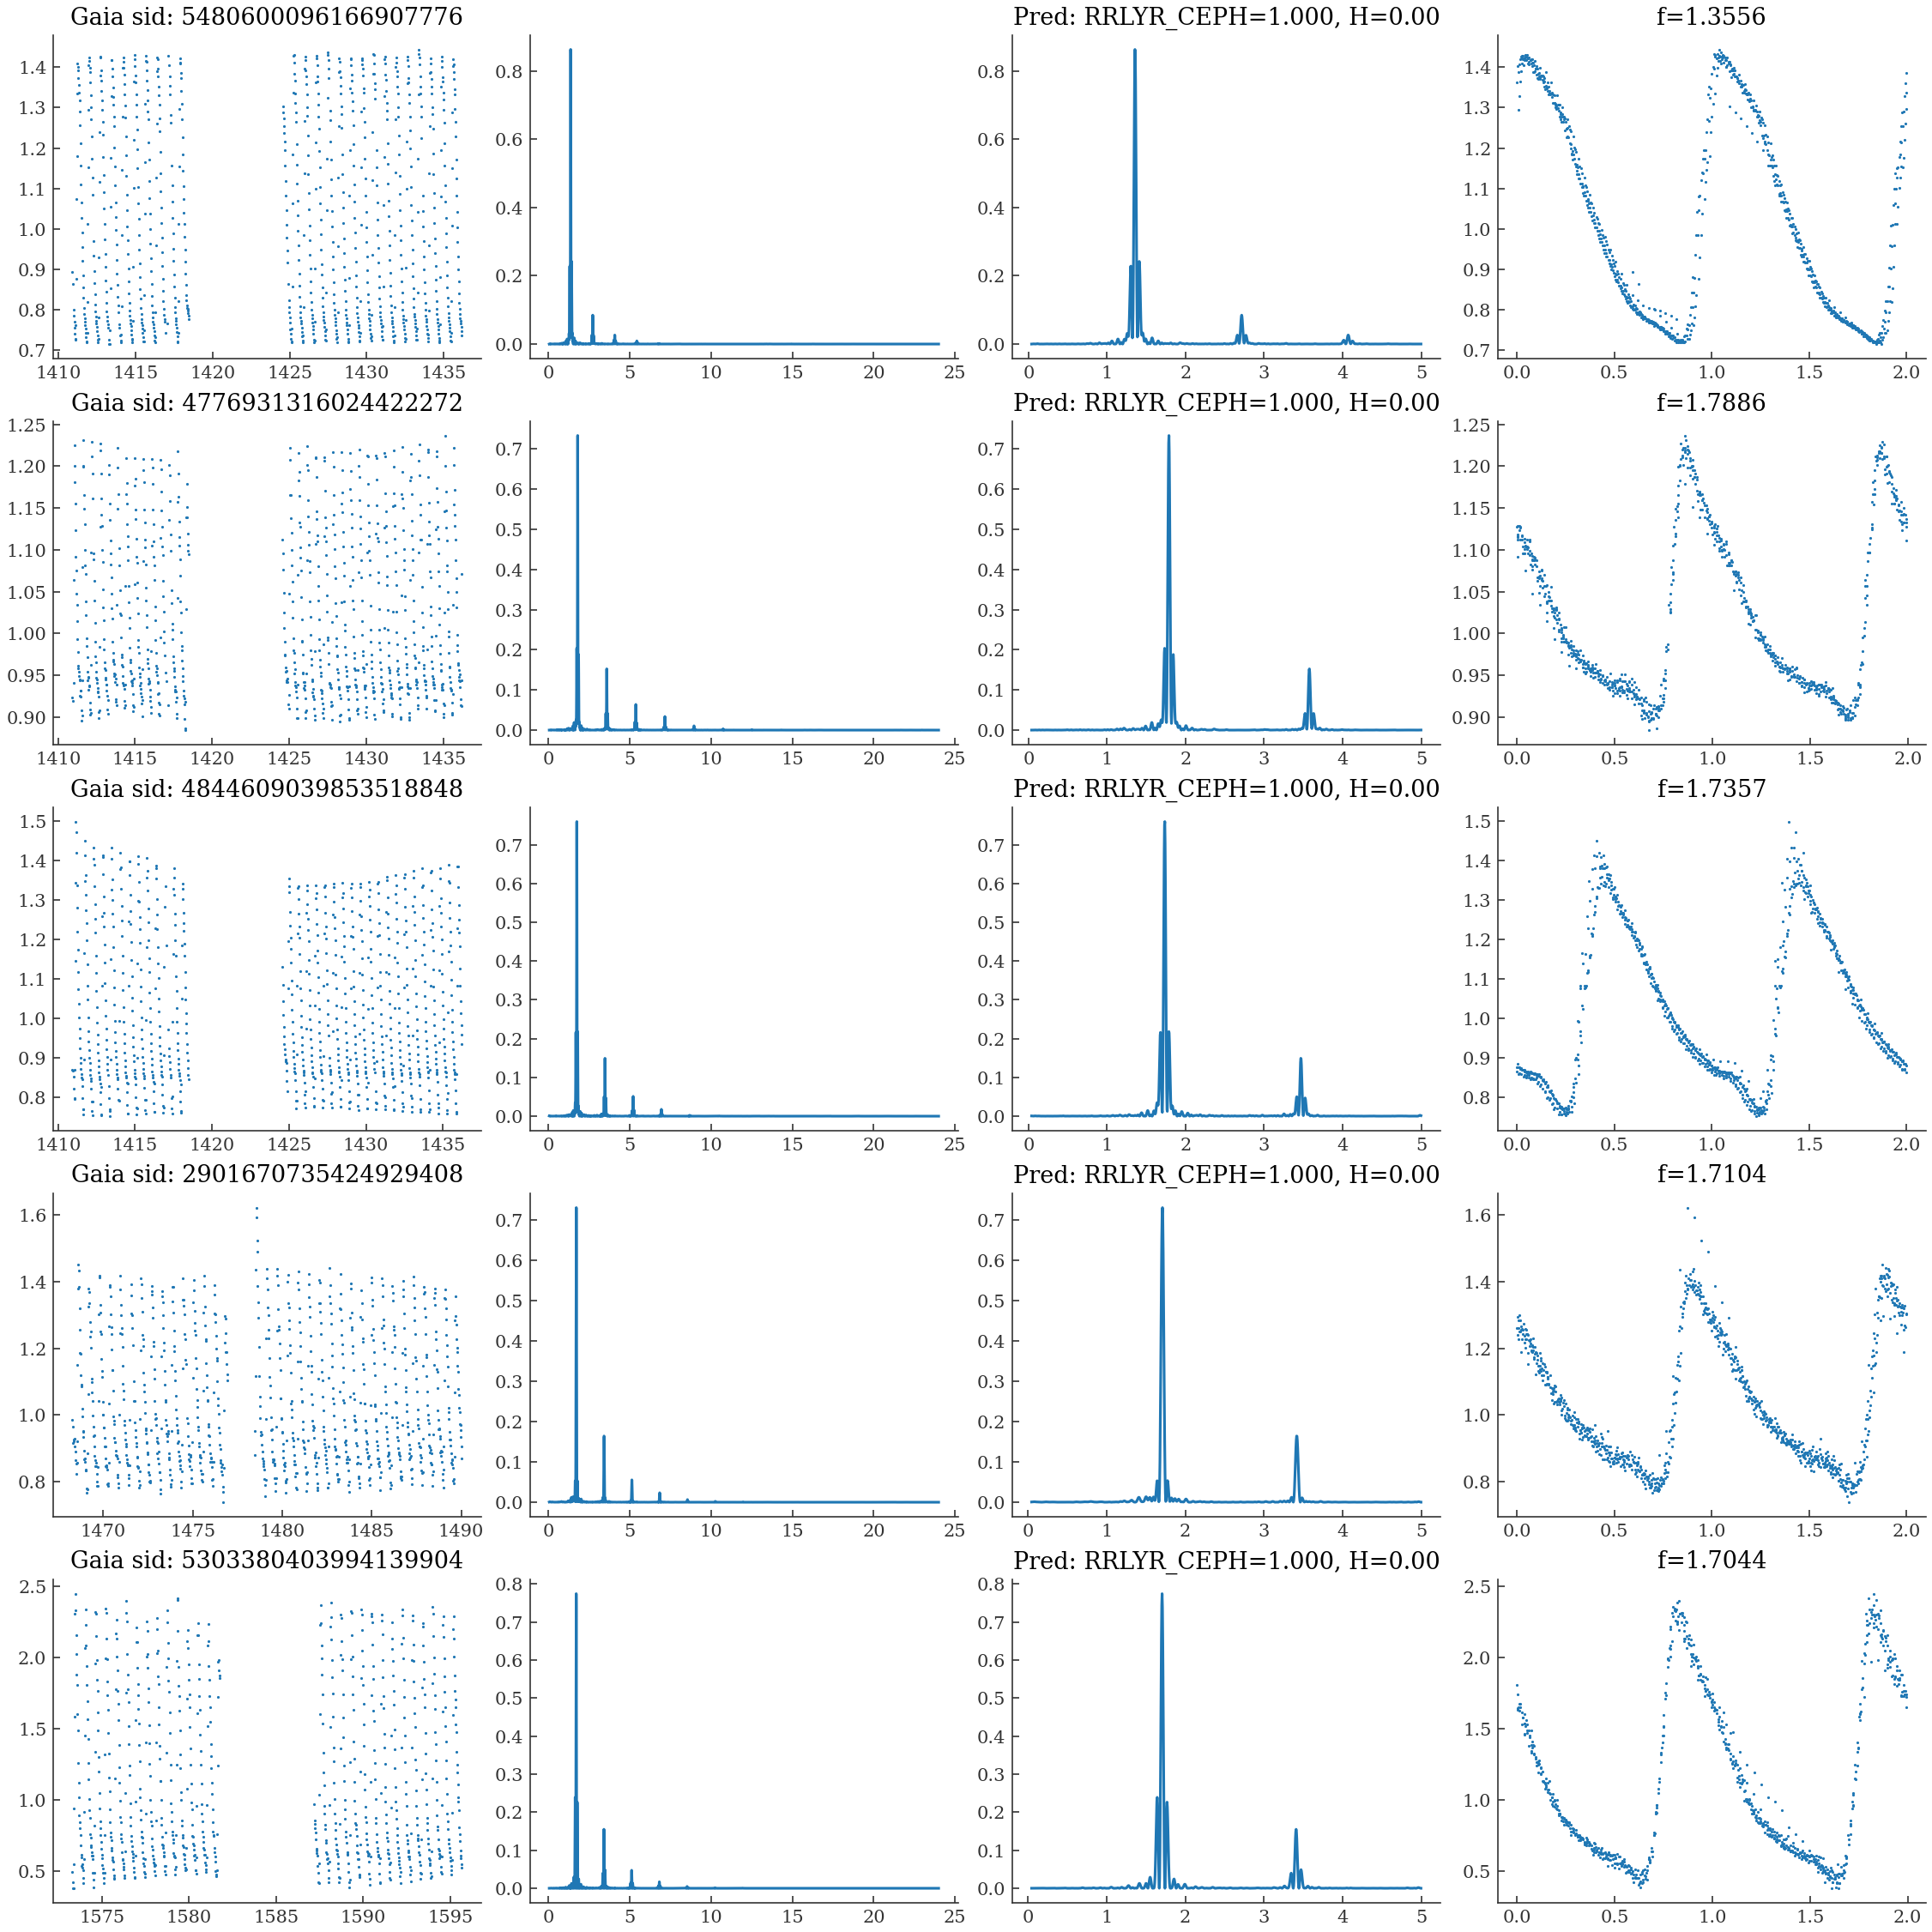

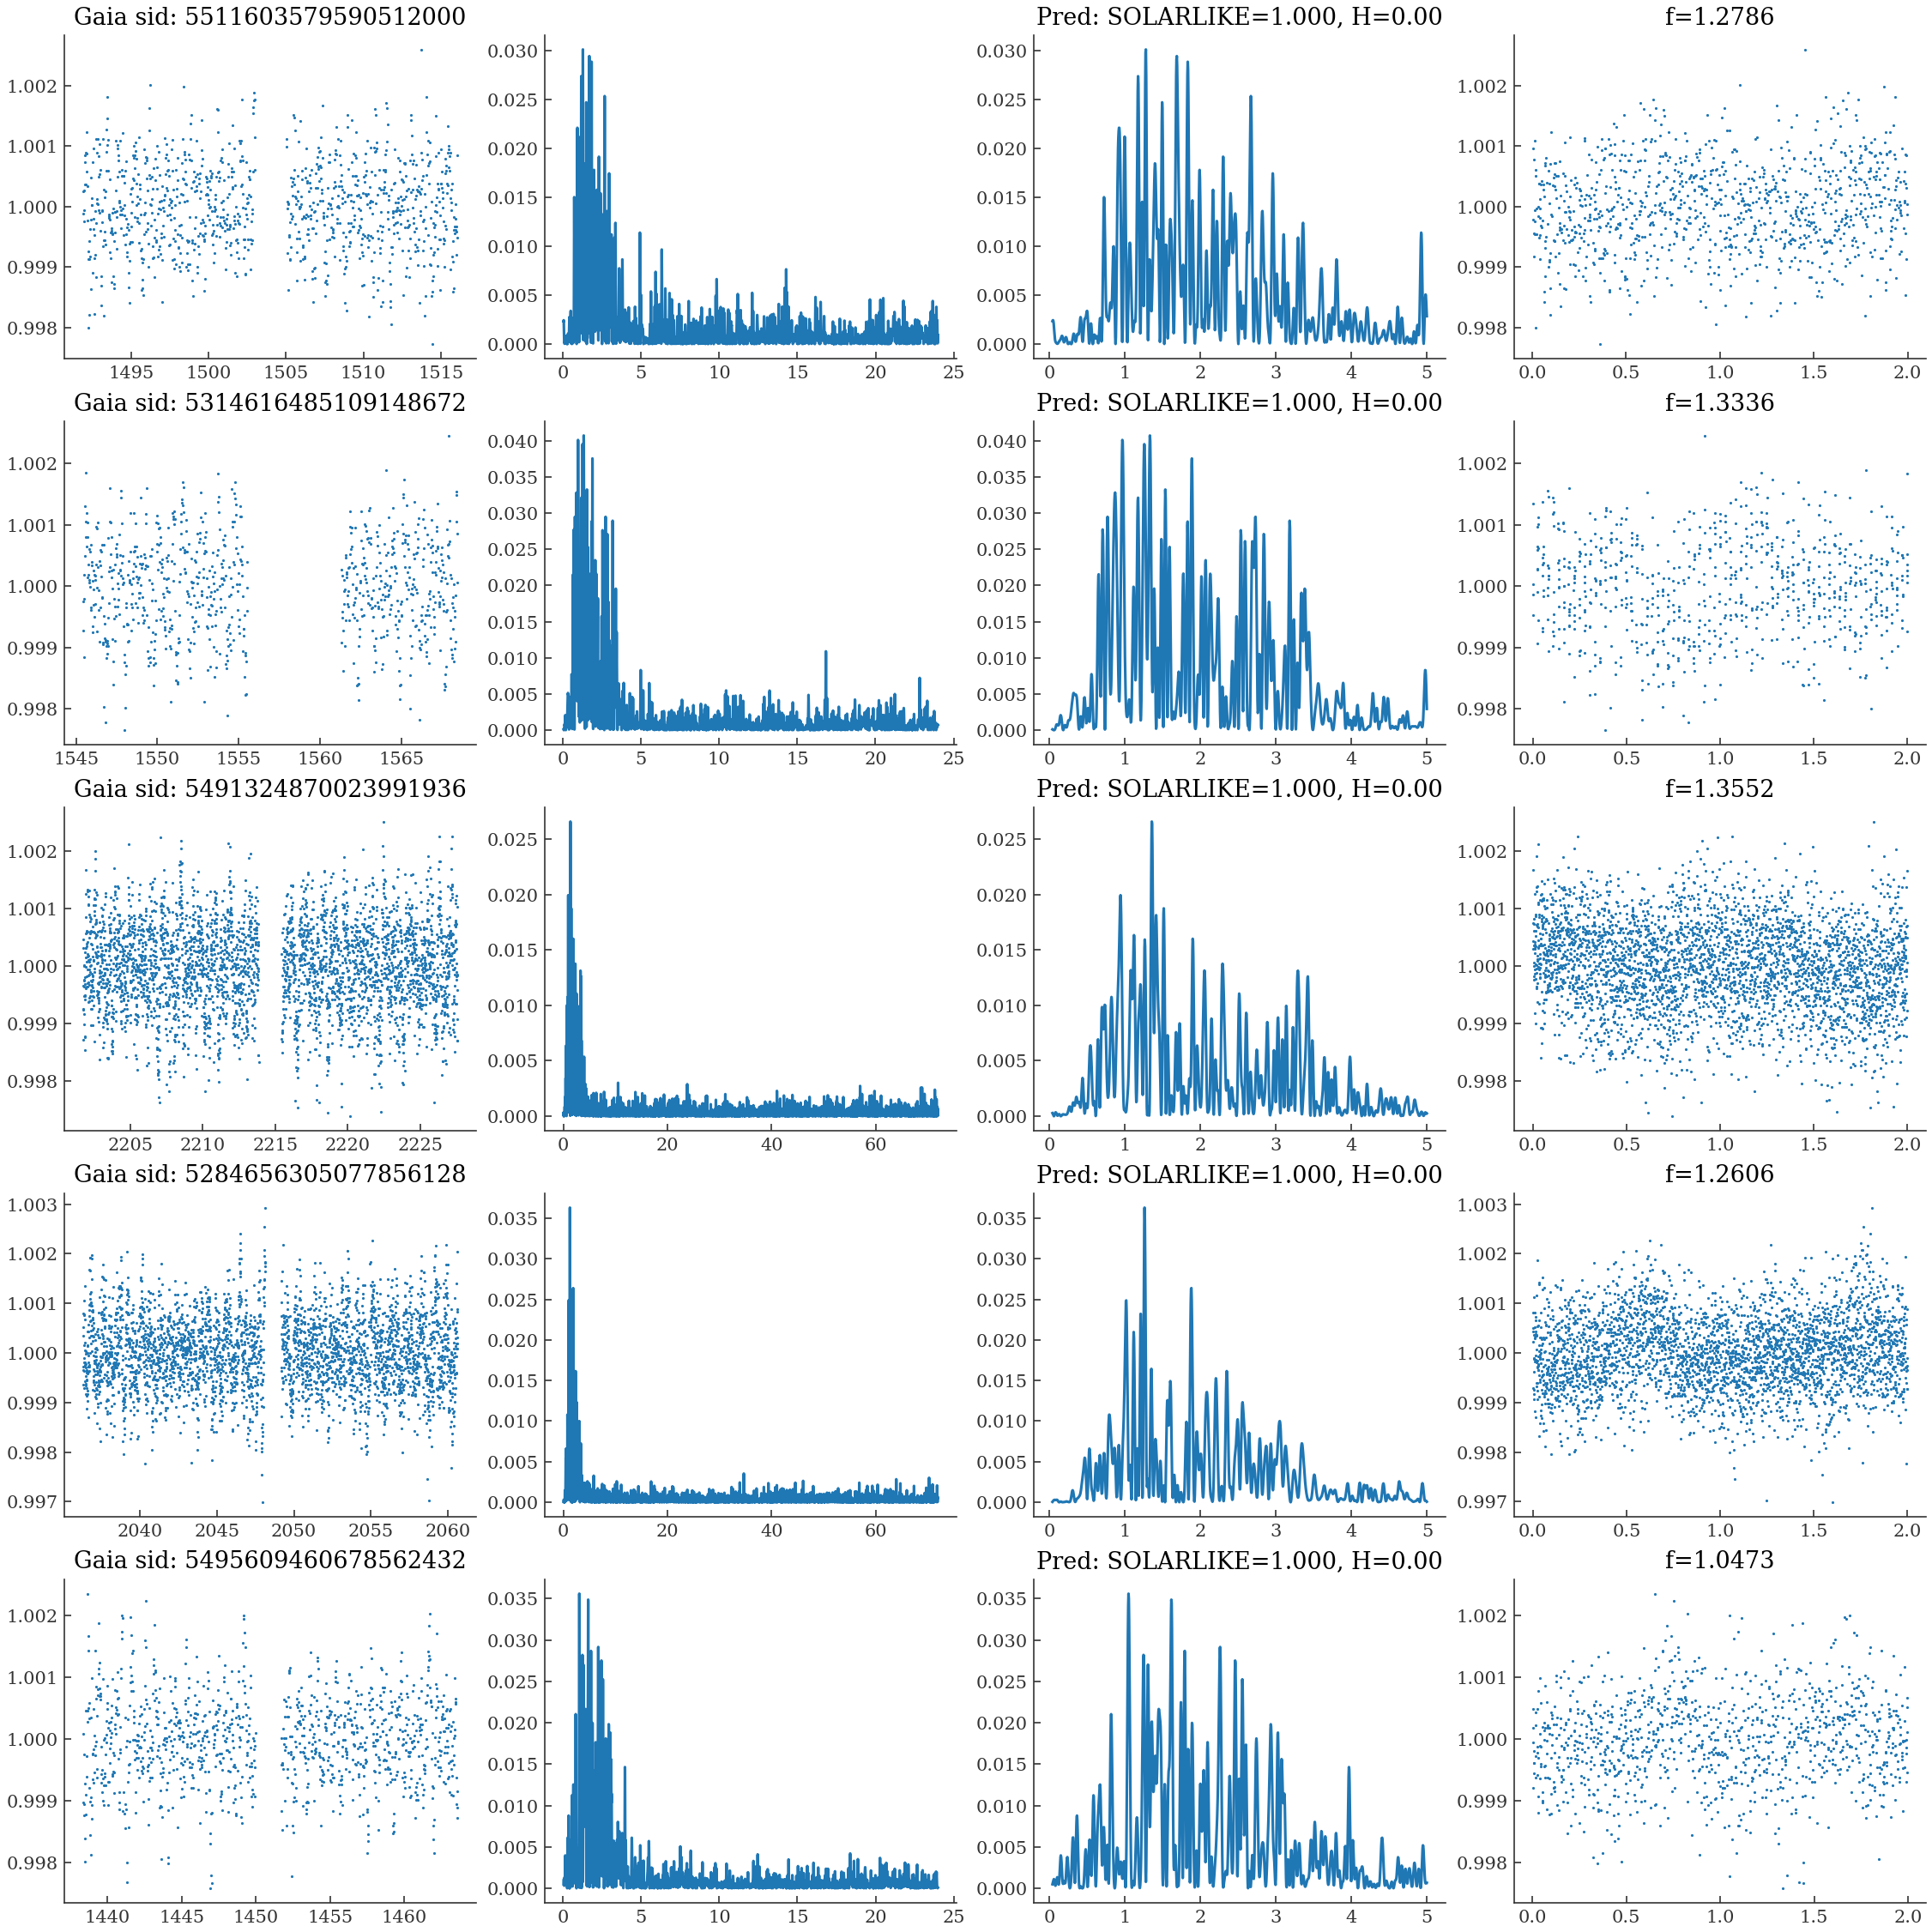

In [4]:
# Top 20 per class
for analysis_class in le.classes_:
    sub_df = df_all_preds.filter(pl.col('best_class').eq(analysis_class)).sort('best_proba', descending=True).head(5)
    n_plots = sub_df.height
    fig, axs = plt.subplots(max(2, n_plots), 4, figsize=(15, 3*n_plots), constrained_layout=True, sharex=False)
    for row, ax in zip(sub_df.iter_rows(named=True), axs):
        path_, proba, entropy, sid = row['path'], row['best_proba'], row['entropy'], row['GaiaDR3']
        ax[0].set_title(f"Gaia sid: {sid}")
        ax[2].set_title(f"Pred: {analysis_class}={proba:0.3f}, H={entropy:0.2f}")
        lc = read_fits_lc(path_)
        time_pre, flux_pre = preprocess_lc(lc.time, lc.cal_flux, lc.sector, cfg)
        ax[0].scatter(time_pre, flux_pre, s=1)
        freq, ampl, _ = compute_periodogram(time_pre, flux_pre)
        best_freq = freq[np.argmax(ampl)]
        ax[-3].plot(freq, ampl)
        ax[-2].plot(freq[freq<5], ampl[freq<5])
        ax[-1].set_title(f"f={best_freq:0.4f}")
        ax[-1].scatter(np.mod(time_pre, 2/best_freq)*best_freq, flux_pre, s=1)

# Junk ratio per sector

(80.0, 100.0)

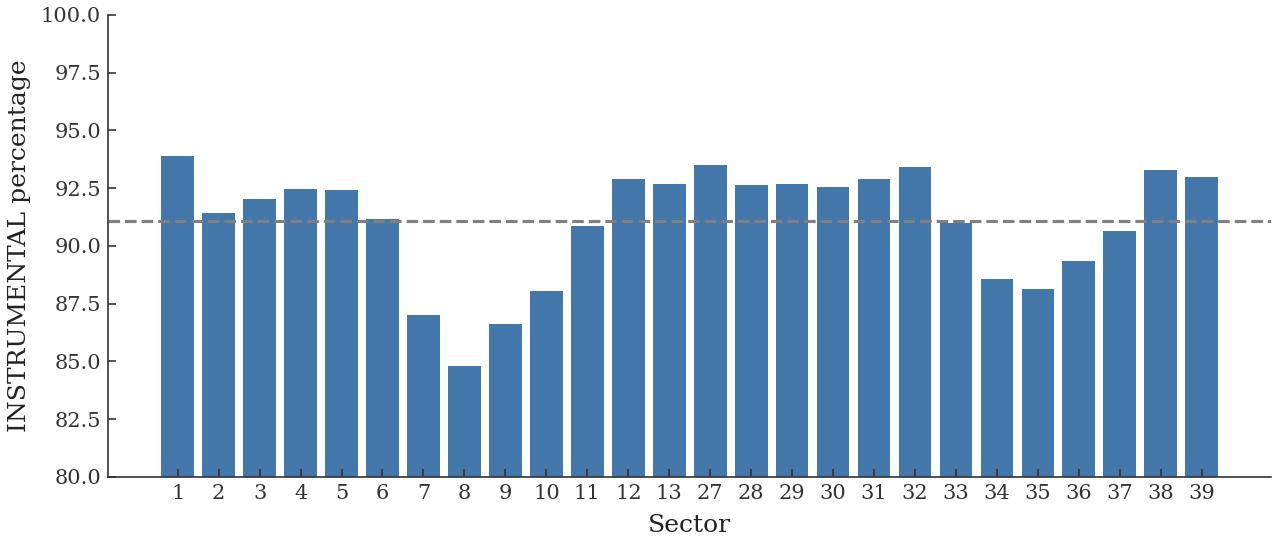

In [5]:
df_junk_per_sector = df_all_preds.group_by("sector").agg(
    n_total=pl.len(),
    n_instr_junk=pl.col("best_class").eq("INSTRUMENTAL").sum(),
    pct_instr_junk=pl.col("best_class").eq("INSTRUMENTAL").mean() * 100,
).sort("sector")
sector = df_junk_per_sector['sector'].to_numpy()
junk_perc = df_junk_per_sector['pct_instr_junk'].to_numpy()
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar([str(s) for s in sector], junk_perc)
mean_pct = junk_perc.mean()
ax.axhline(mean_pct, ls="--", color="grey", label=f"mean = {mean_pct:.1f}%")
ax.set_xlabel('Sector')
ax.set_ylabel('INSTRUMENTAL percentage')
ax.set_ylim(80, 100)

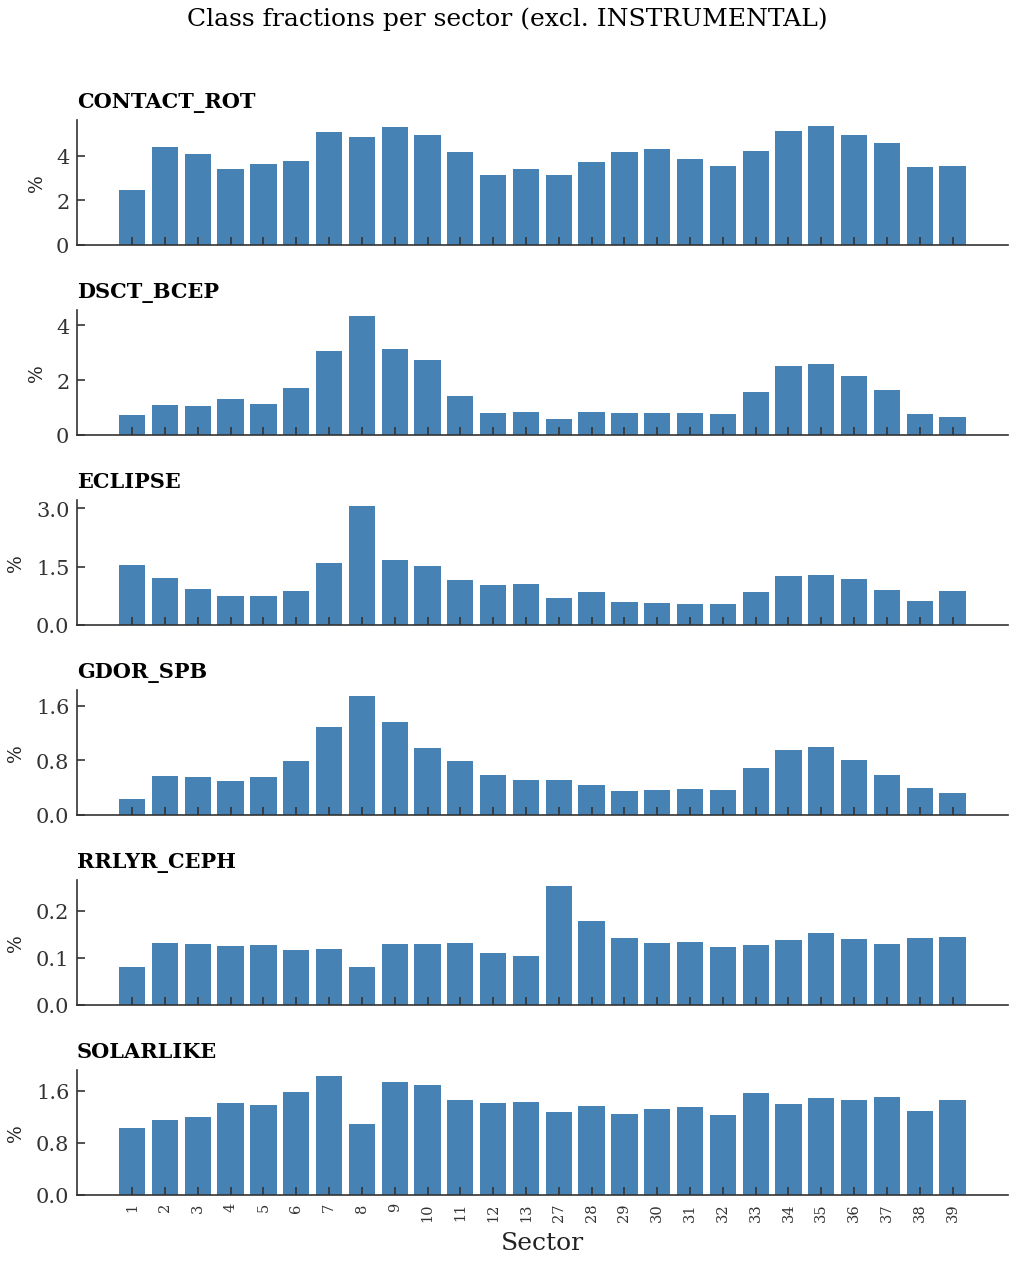

In [9]:
classes_no_instr = [
    "CONTACT_ROT", "DSCT_BCEP", "ECLIPSE",
    "GDOR_SPB", "RRLYR_CEPH", "SOLARLIKE",
]

pct_df = df_all_preds.group_by("sector").agg(
    [
        (pl.col("best_class").eq(c).mean() * 100).alias(c)
        for c in classes_no_instr
    ]
).sort("sector")
sectors = pct_df["sector"].to_numpy()

fig, axes = plt.subplots(len(classes_no_instr), 1,
                         figsize=(7, 1.4 * len(classes_no_instr)),
                         sharex=True)

for ax, cls in zip(axes, classes_no_instr):
    vals = pct_df[cls].to_numpy()
    ax.bar([str(s) for s in sectors], vals, color="steelblue")
    ax.set_ylabel("%", fontsize=9)
    ax.set_title(cls, fontsize=10, loc="left", fontweight="bold")
    ax.yaxis.set_major_locator(plt.MaxNLocator(3))

axes[-1].tick_params(axis="x", rotation=90, labelsize=7)
axes[-1].set_xlabel("Sector")
fig.suptitle("Class fractions per sector (excl. INSTRUMENTAL)",
             fontsize=12, y=1.01)
fig.tight_layout()

# Frequency and amplitude distributions

In [10]:
#  Training features for contrasting

df_training_features = pl.read_parquet(
    '../results/features/training_set_v13/', columns=['path', 'ls_frequency_dominant', 'ls_amplitude_dominant']
).join(df_training_set, on='path')

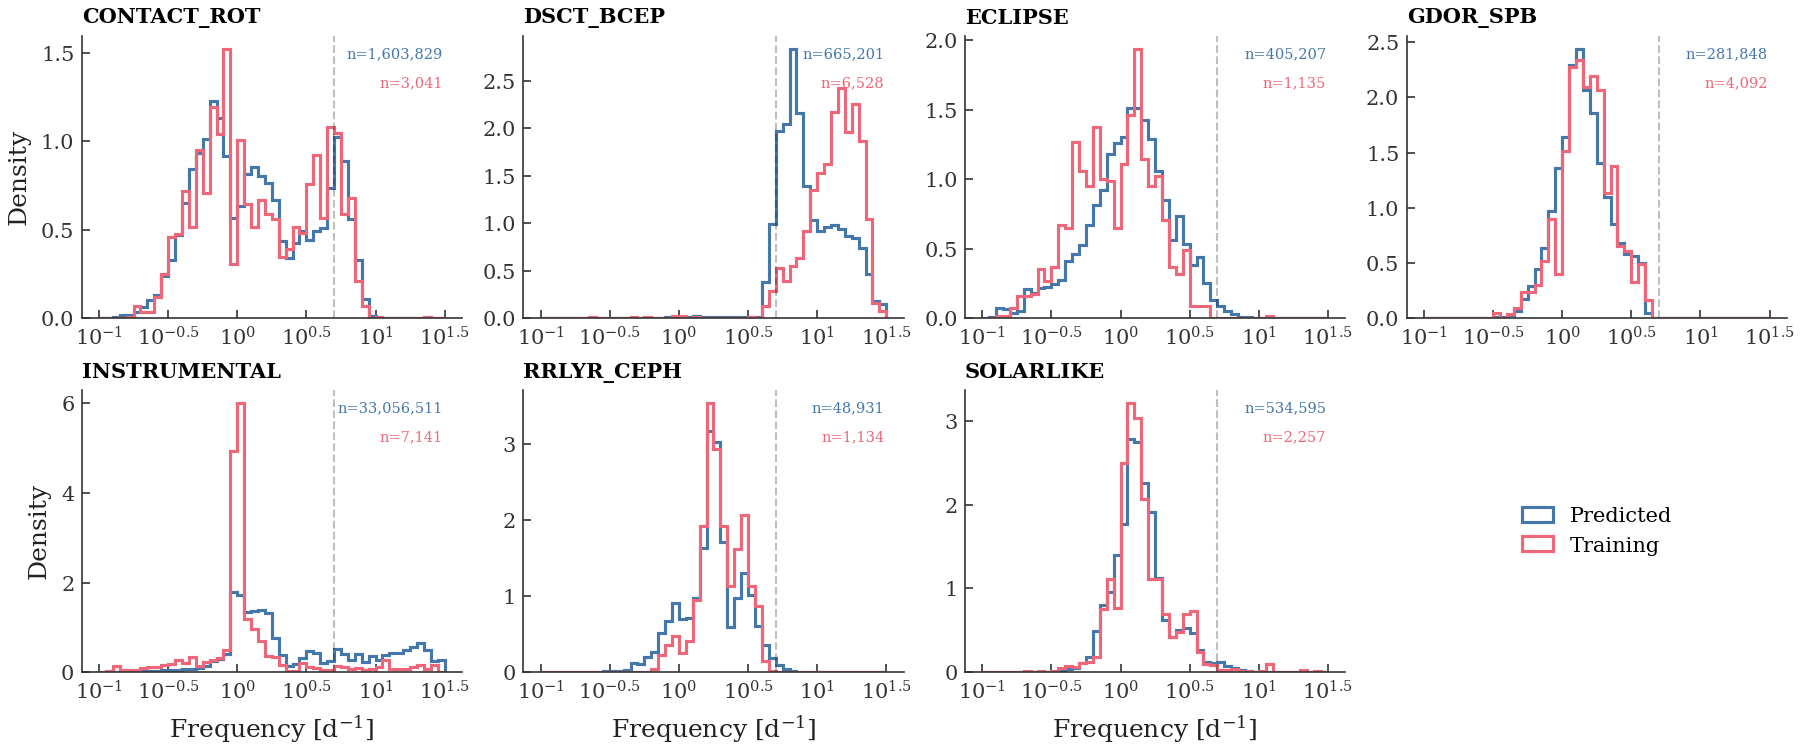

In [11]:
fig, axs = plt.subplots(2, 4, figsize=(12, 5), constrained_layout=True)

for name, ax in zip(le.classes_, axs.ravel()):
    pred_freq = np.log10(
        df_all_preds.filter(pl.col("best_class").eq(name))["ls_frequency_dominant"].to_numpy()
    )
    train_freq = np.log10(
        df_training_features.filter(pl.col("label").eq(name))["ls_frequency_dominant"].to_numpy()
    )

    bins = np.linspace(-1, 1.5, 51)
    ax.hist(pred_freq, bins=bins, density=True,
            histtype="step", linewidth=1.5, color="#4477AA", label="Predicted")
    ax.hist(train_freq, bins=bins, density=True,
            histtype="step", linewidth=1.5, color="#EE6677", label="Training")
    ax.set_title(name, fontsize=10, loc="left", fontweight="bold")

    # Add count annotations
    ax.text(0.95, 0.92, f"n={len(pred_freq):,}",
            transform=ax.transAxes, fontsize=7, ha="right", color="#4477AA")
    ax.text(0.95, 0.82, f"n={len(train_freq):,}",
            transform=ax.transAxes, fontsize=7, ha="right", color="#EE6677")
    ax.axvline(np.log10(5), ls='--', lw=1, c='k', alpha=0.25)

axs.ravel()[-1].axis("off")

# Single legend in the empty panel
axs.ravel()[-1].legend(
    *axs.ravel()[0].get_legend_handles_labels(),
    loc="center", fontsize=10, frameon=False,
)

for ax in axs[:, 0]:
    ax.set_ylabel("Density")

# Remove redundant labels on inner panels
for ax in axs[0]:
    ax.set_xlabel("")
for ax in axs[:, 1:].ravel():
    ax.set_ylabel("")
    
import matplotlib.ticker as mticker

# After plotting, apply to all axes:
for ax in axs.ravel()[:-1]:  # skip the empty panel
    ax.xaxis.set_major_locator(mticker.FixedLocator([-1, -0.5, 0, 0.5, 1, 1.5]))
    ax.xaxis.set_major_formatter(
        mticker.FuncFormatter(lambda x, _: rf"$10^{{{x:g}}}$")
    )

for ax in axs[1]:
    ax.set_xlabel(r"Frequency [d$^{-1}$]")

# Class/sector/source consistency

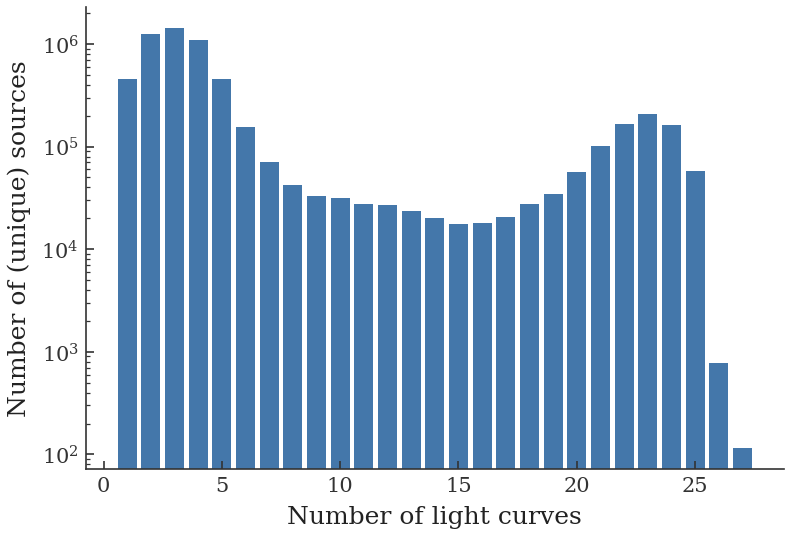

In [12]:
x, h = df_all_preds.drop('path').group_by('GaiaDR3').len().rename({'len': 'n_lc'}).group_by('n_lc').len().sort('n_lc').to_numpy().T
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(x, h)
ax.set_xlabel('Number of light curves')
ax.set_ylabel('Number of (unique) sources')
ax.set_yscale('log')

In [13]:
%%time

CLASS_COLS = [
    "CONTACT_ROT", "DSCT_BCEP", "ECLIPSE",
    "GDOR_SPB", "INSTRUMENTAL", "RRLYR_CEPH", "SOLARLIKE"
]

counts = df_all_preds.group_by(["GaiaDR3", "best_class"]).agg(
    pl.len().alias("n_class"),
    pl.mean("best_proba").alias("proba_mean_class"),
    pl.mean("entropy").alias("entropy_mean_class"),
)

source_summary = counts.group_by("GaiaDR3").agg(
    pl.sum("n_class").alias("n_sectors"),
    pl.col("best_class").sort_by("n_class", descending=True).first().alias("consensus_class"),
    #pl.col("n_class").max().alias("modal_class_count"),
    (pl.col("n_class").max() / pl.sum("n_class")).alias("consensus_fraction"),
    pl.col("best_class").alias("n_unique_classes"),
).with_columns(pl.col('n_unique_classes').list.len())

mean_probs_and_freqs = df_all_preds.group_by("GaiaDR3").agg(
    *[pl.mean(c).alias(f"{c}_mean") for c in CLASS_COLS],
    pl.col('ls_amplitude_dominant').mean().alias('ls_amplitude_mean'),
    pl.col('ls_amplitude_dominant').std().alias('ls_amplitude_std'),
    pl.col('ls_frequency_dominant').mean().alias('ls_frequency_mean'),
    pl.col('ls_frequency_dominant').std().alias('ls_frequency_std'),
)

source_summary = source_summary.join(mean_probs_and_freqs, on='GaiaDR3')
source_summary.tail(10)

CPU times: user 1min 7s, sys: 1.82 s, total: 1min 9s
Wall time: 5.63 s


GaiaDR3,n_sectors,consensus_class,consensus_fraction,n_unique_classes,CONTACT_ROT_mean,DSCT_BCEP_mean,ECLIPSE_mean,GDOR_SPB_mean,INSTRUMENTAL_mean,RRLYR_CEPH_mean,SOLARLIKE_mean,ls_amplitude_mean,ls_amplitude_std,ls_frequency_mean,ls_frequency_std
i64,u32,str,f64,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
4651712231737684096,21,"""INSTRUMENTAL""",0.952381,2,0.049096,0.00013,0.000718,0.000279,0.946402,0.000004,0.003372,0.043048,0.056413,2.405423,3.27908
5533632329422194432,3,"""INSTRUMENTAL""",1.0,1,0.000829,0.005257,0.00001,0.000027,0.993528,0.000002,0.000347,0.036429,0.050201,2.322722,2.024695
5485994304510879744,13,"""INSTRUMENTAL""",0.923077,2,0.044895,0.000101,0.000034,0.000102,0.92665,0.000001,0.028217,0.018001,0.016316,12.935098,19.842534
5544682558717891584,3,"""INSTRUMENTAL""",1.0,1,0.272008,0.000596,0.000191,0.000629,0.708004,0.001636,0.016935,0.089349,0.013159,0.604873,0.108241
5537351255701464960,2,"""INSTRUMENTAL""",1.0,1,0.000049,0.000003,0.000004,0.000002,0.99812,1.9832e-7,0.001823,0.012721,0.000635,1.302479,0.200721
5536561600190142592,3,"""INSTRUMENTAL""",1.0,1,0.017036,0.000111,0.000305,0.000008,0.980773,0.000015,0.001752,0.026779,0.019775,1.860164,1.127067
5328614157182957824,4,"""INSTRUMENTAL""",1.0,1,9.0459e-7,0.000005,3.7129e-7,5.6427e-7,0.999984,1.5522e-7,0.000009,0.014653,0.009671,3.697666,1.424618
5522303236479017728,2,"""INSTRUMENTAL""",1.0,1,0.000021,0.000231,0.000002,0.000002,0.994987,0.000002,0.004753,0.015954,0.010909,2.957094,1.9957
5531424372630824320,2,"""INSTRUMENTAL""",1.0,1,0.000037,0.000957,0.000003,0.000002,0.998917,0.000002,0.000083,0.018579,0.016888,8.91055,9.206777


Text(0, 0.5, 'Mean consensus class fraction')

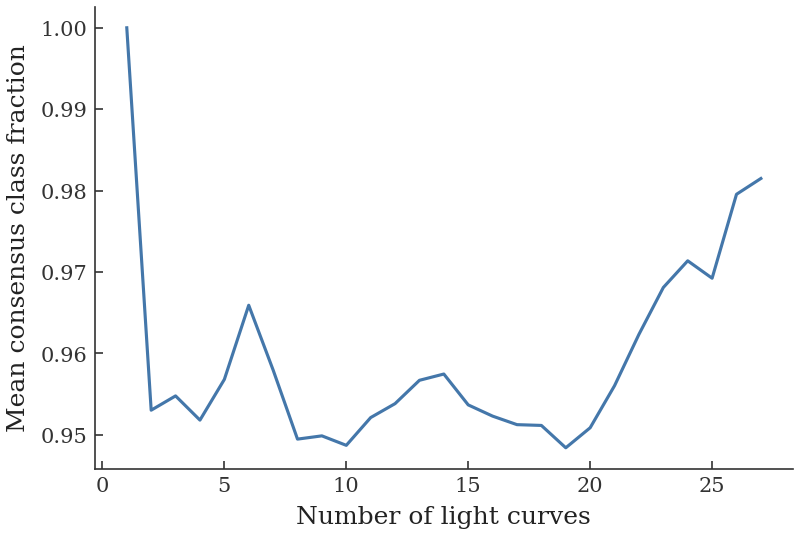

In [15]:
x, y = source_summary.group_by('n_sectors').mean().sort('n_sectors')[['n_sectors', 'consensus_fraction']].to_numpy().T
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(x, y)
ax.set_xlabel('Number of light curves')
ax.set_ylabel('Mean consensus class fraction')

In [16]:
# source_summary.filter(pl.col('num_sectors').gt(1)).filter(pl.col('modal_class_fraction').ge(0.9)).height/source_summary.filter(pl.col('num_sectors').gt(1)).height

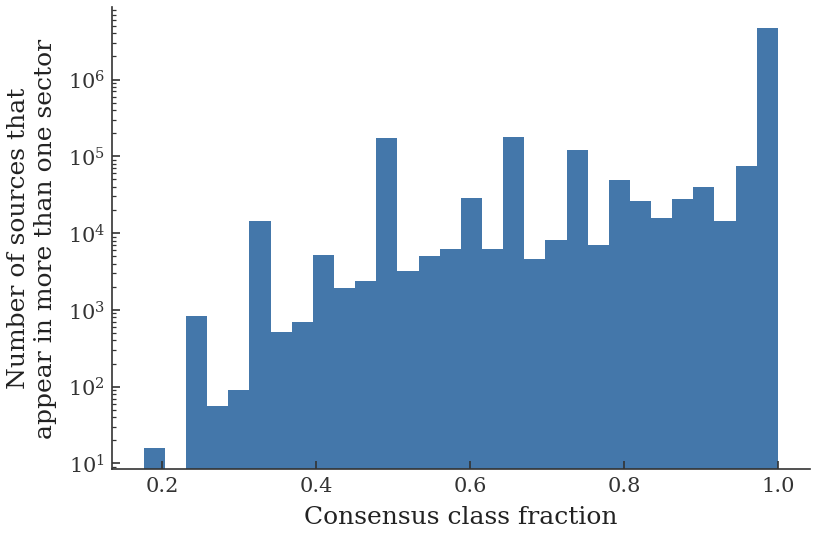

In [17]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(source_summary.filter(pl.col('n_sectors').gt(1))['consensus_fraction'].to_numpy(), bins=30);
ax.set_xlabel('Consensus class fraction')
ax.set_ylabel('Number of sources that\nappear in more than one sector')
ax.set_yscale('log')

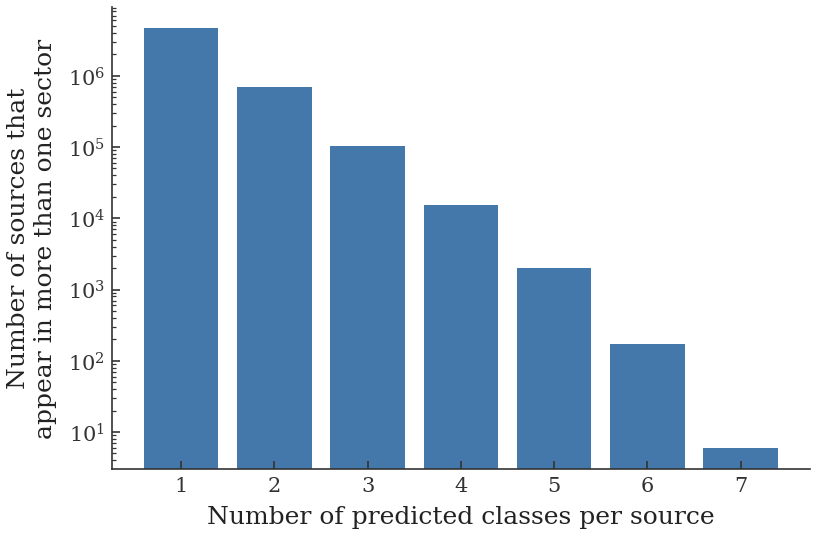

In [18]:
x, h = source_summary.filter(pl.col('n_sectors').gt(1)).group_by('n_unique_classes').len().sort('n_unique_classes').to_numpy().T
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(x, h)
ax.set_xlabel('Number of predicted classes per source')
ax.set_ylabel('Number of sources that\nappear in more than one sector')
ax.set_yscale('log')

In [20]:
# most common confusions for the 2 n_unique classes case

df_all_preds.join(
    source_summary.filter(pl.col('n_unique_classes').eq(2)),
    on='GaiaDR3'
).drop('path').group_by('GaiaDR3').agg(
    pl.col("best_class").unique().alias("best_class_list")
).group_by('best_class_list').len().sort('len').tail(10)

best_class_list,len
list[str],u32
"[""GDOR_SPB"", ""INSTRUMENTAL""]",12214
"[""INSTRUMENTAL"", ""GDOR_SPB""]",13087
"[""ECLIPSE"", ""INSTRUMENTAL""]",31497
"[""INSTRUMENTAL"", ""ECLIPSE""]",37544
"[""SOLARLIKE"", ""INSTRUMENTAL""]",40051
"[""INSTRUMENTAL"", ""SOLARLIKE""]",48713
"[""DSCT_BCEP"", ""INSTRUMENTAL""]",71061
"[""INSTRUMENTAL"", ""DSCT_BCEP""]",93993
"[""CONTACT_ROT"", ""INSTRUMENTAL""]",94222


In [23]:
source_summary.group_by('consensus_class').len().join(
    source_summary.filter(
        pl.col('consensus_fraction').gt(0.9)
    ).group_by('consensus_class').len().rename(
        {'len':'len_filtered'}
    ), on='consensus_class'
).sort('consensus_class').with_columns(
    pl.col('len_filtered').truediv('len').alias('filt_percent')
)

consensus_class,len,len_filtered,filt_percent
str,u32,u32,f64
"""CONTACT_ROT""",262190,150612,0.574438
"""DSCT_BCEP""",146038,90197,0.617627
"""ECLIPSE""",81095,55714,0.687021
"""GDOR_SPB""",61788,33886,0.548424
"""INSTRUMENTAL""",5343588,4914353,0.919673
"""RRLYR_CEPH""",7177,4155,0.578933
"""SOLARLIKE""",85454,44231,0.5176


# Color magnitude diagrams

In [92]:
pl.scan_parquet(
    "/STER/mamsie/tess/TIC/plato_fov/cat_v1_no_path.parquet"
).unique('GaiaDR3').select(pl.len()).collect().item()

6040326

In [46]:
df_gaia_radec = pl.scan_parquet(
    "/STER/mamsie/tess/TIC/plato_fov/cat_v1_no_path.parquet"
).select(['GaiaDR3', 'TIC', 'Teff','L', 'RA', 'DEC', 'BP_RP', 'ncams']).unique('GaiaDR3').join(
    pl.scan_parquet('../flux_ratios.parquet'), on='GaiaDR3'
).collect()

In [49]:
source_summary_radec = source_summary.join(df_gaia_radec, on='GaiaDR3')

In [50]:
source_summary_radec.head(5)

GaiaDR3,n_sectors,consensus_class,consensus_fraction,n_unique_classes,CONTACT_ROT_mean,DSCT_BCEP_mean,ECLIPSE_mean,GDOR_SPB_mean,INSTRUMENTAL_mean,RRLYR_CEPH_mean,SOLARLIKE_mean,ls_amplitude_mean,ls_amplitude_std,ls_frequency_mean,ls_frequency_std,TIC,Teff,L,RA,DEC,BP_RP,ncams,Gmag,flux_frac
i64,u32,str,f64,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,f64,f32,f64,f64,f32,i64,f32,f32
4879395972848553728,2,"""INSTRUMENTAL""",1.0,1,0.000003,0.000002,5.3268e-7,2.3343e-7,0.999986,2.2058e-7,0.000008,0.011122,0.007447,8.071929,9.212265,178969129,4953.0,0.273303,69.639108,-28.893455,1.136263,6,14.406223,0.291121
5319712962023337600,4,"""INSTRUMENTAL""",1.0,1,0.000051,0.000082,0.000007,0.000015,0.992265,5.4464e-7,0.007579,0.018102,0.012989,1.375944,0.25606,342678047,5998.0,2.440718,125.164648,-53.973446,1.085802,6,15.241292,0.015181
5502187877404415488,4,"""ECLIPSE""",1.0,1,0.000019,0.00003,0.999182,4.4553e-7,0.000768,1.0065e-7,3.4459e-8,0.082712,0.007643,0.537383,0.33323,238024601,5634.0,2.395811,103.153998,-50.468102,0.888069,24,14.416875,0.103948
2925446815385228032,3,"""INSTRUMENTAL""",1.0,1,0.000029,0.000036,0.000003,0.000002,0.996422,0.000001,0.003507,0.022915,0.016245,1.377431,0.441298,48613704,4887.0,0.728915,100.198777,-23.427655,1.201432,6,16.503986,0.012375
5289706877381362176,13,"""INSTRUMENTAL""",1.0,1,0.000274,0.000349,0.001282,0.00005,0.997707,5.0164e-7,0.000337,0.021785,0.017596,1.025767,0.825094,308541592,null,null,121.022477,-62.081813,1.680157,12,13.29958,0.245593


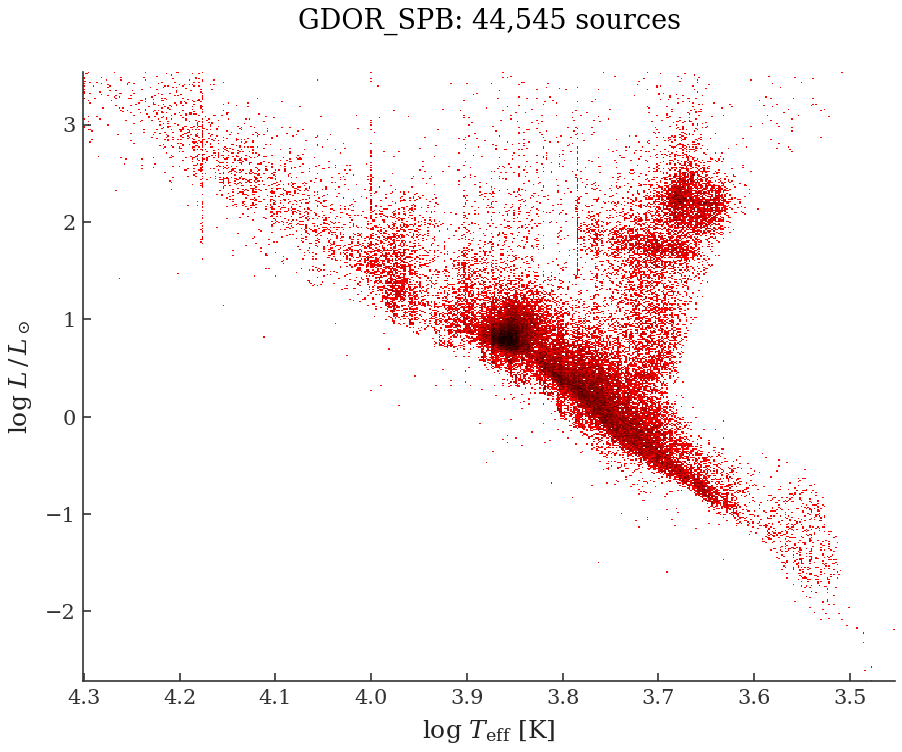

In [71]:
from matplotlib.colors import LinearSegmentedColormap, LogNorm

topcat_density = LinearSegmentedColormap.from_list(
    'topcat_density', ['red', 'black']
)

def cmd_density(df, x_col='Teff', y_col='L', bins=500, cmap='Blues', figsize=(6, 5), title='', subtitle=''):
    x = df[x_col].log10().to_numpy()
    y = df[y_col].log10().to_numpy()
    mask = np.isfinite(x) & np.isfinite(y)
    x, y = x[mask], y[mask]
    fig, ax = plt.subplots(figsize=figsize, constrained_layout=True)
    h, xedges, yedges = np.histogram2d(x, y, bins=bins)

    ax.imshow(
        h.T,
        origin='lower',
        aspect='auto',
        extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
        norm=LogNorm(vmin=1),
        cmap=topcat_density,
        interpolation='nearest'
    )
    ax.invert_xaxis()
    ax.set_xlabel(r'$\log\,T_\mathrm{eff}$ [K]')
    ax.set_ylabel(r'$\log\,L\,/\,L_\odot$')
    ax.set_title(
        f"{title}: {len(x):,} sources\n"+subtitle,
    )

sel_class = 'GDOR_SPB'

df_cmd = source_summary_radec.filter(
    pl.col('consensus_class').eq(sel_class)
)
    
cmd_density(df_cmd, title=sel_class)

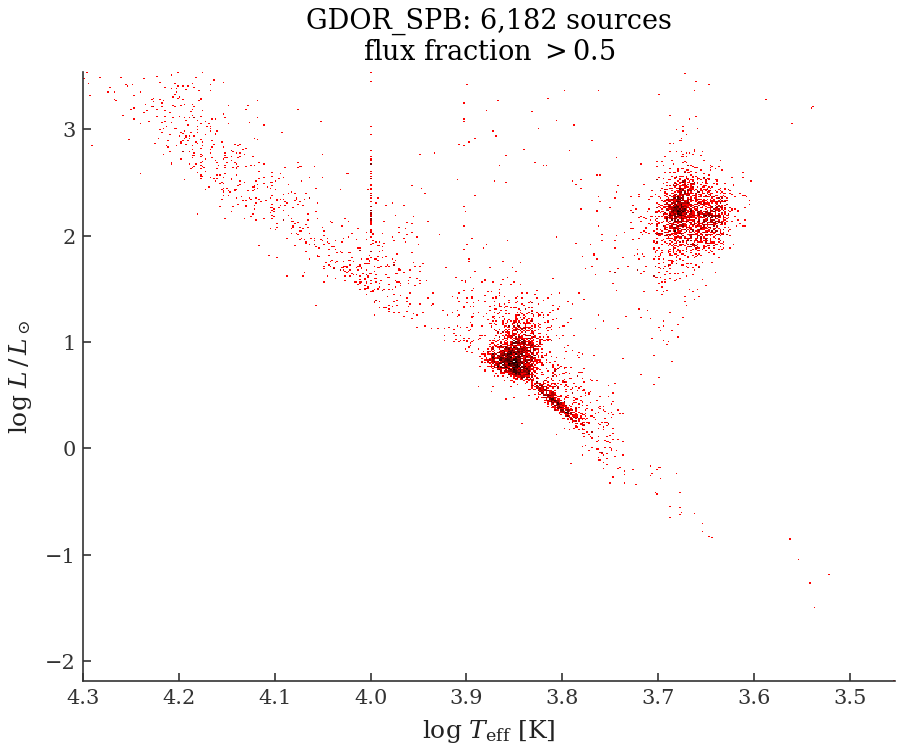

In [79]:
cmd_density(df_cmd.filter(
    pl.col('flux_frac').gt(0.5) 
), title=sel_class, subtitle=r"flux fraction $> 0.5$")

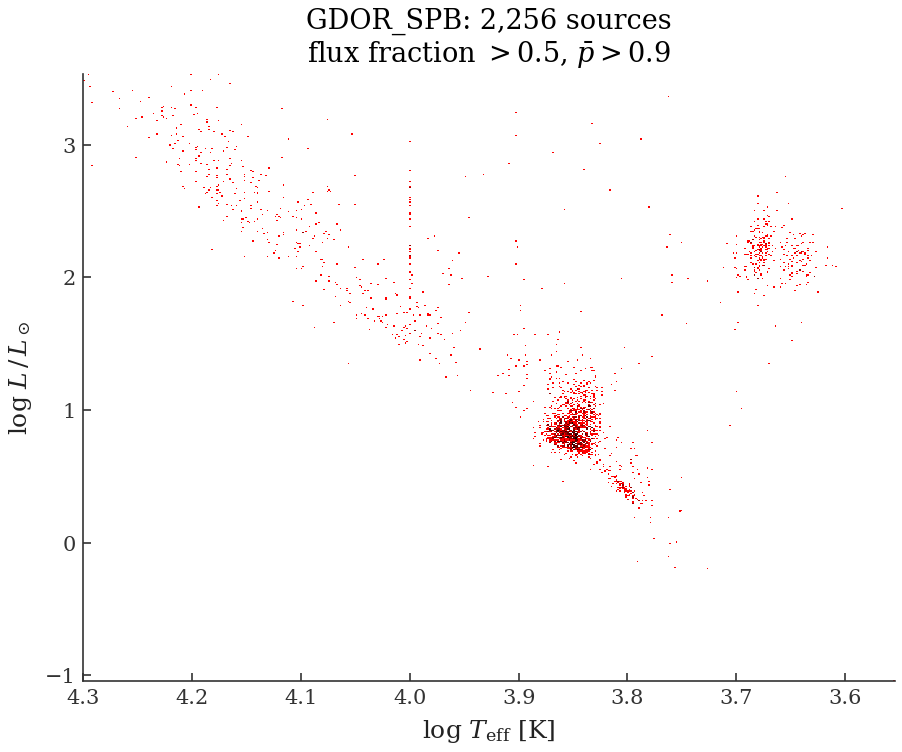

In [80]:
# Filtering by modal class fraction and mean probability

proba_cut = 0.9
cmd_density(df_cmd.filter(
    pl.col('flux_frac').gt(0.5) & pl.col('n_sectors').gt(1) & pl.col('consensus_fraction').gt(proba_cut) & pl.col(f'{sel_class}_mean').gt(proba_cut) 
), title=sel_class, subtitle=r"flux fraction $> 0.5$, $\bar{p} > 0.9$")

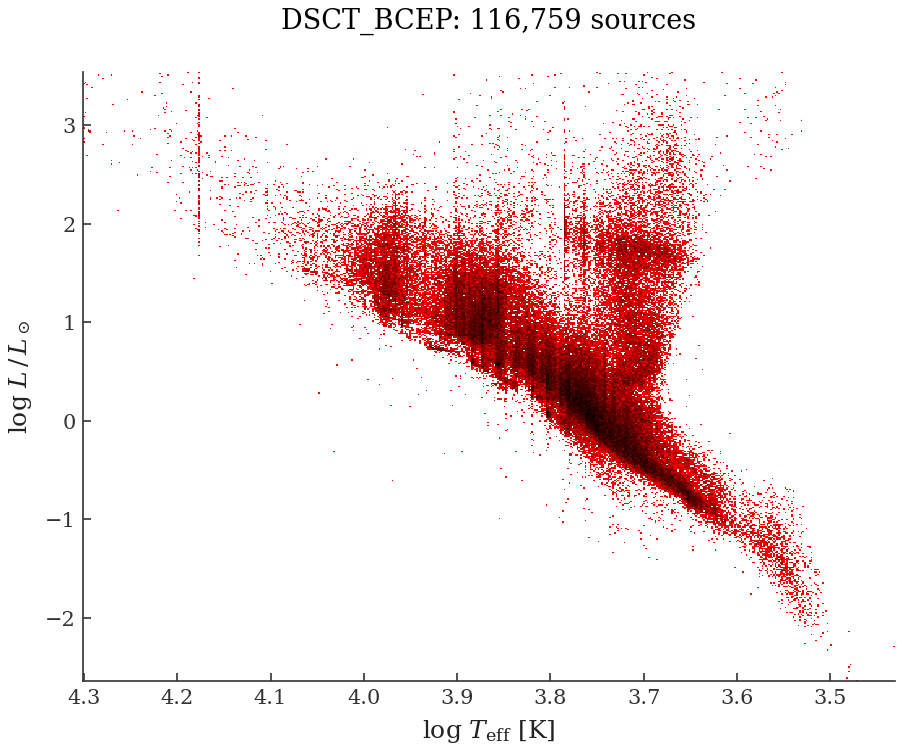

In [81]:
sel_class = 'DSCT_BCEP'

df_cmd = source_summary_radec.filter(
    pl.col('consensus_class').eq(sel_class)
)

cmd_density(df_cmd, title=sel_class)

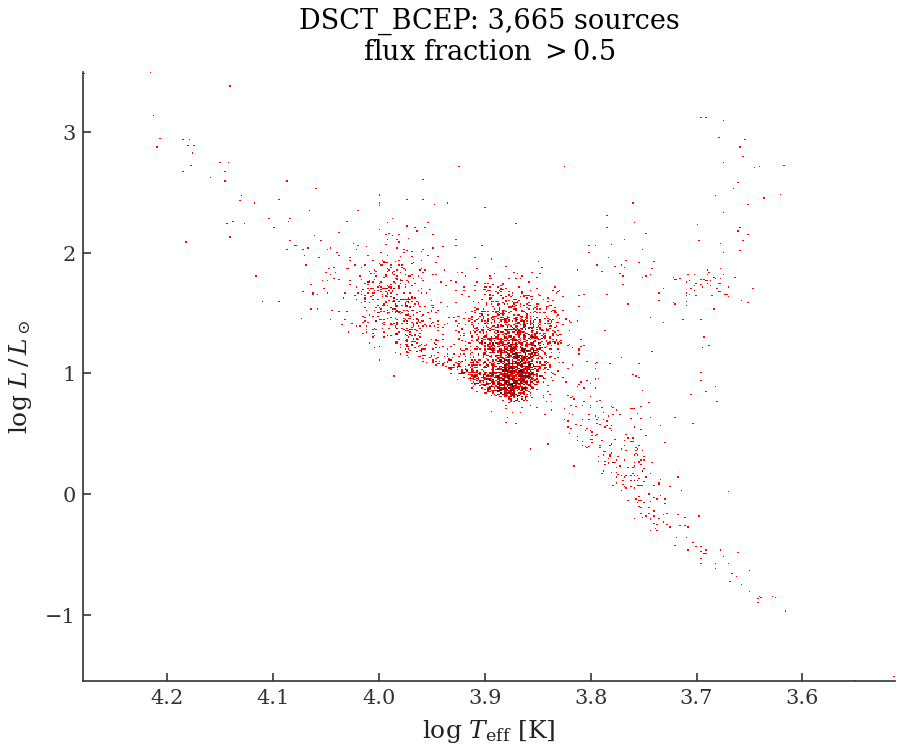

In [82]:
cmd_density(df_cmd.filter(
    pl.col('flux_frac').gt(0.5) 
), title=sel_class, subtitle=r"flux fraction $> 0.5$")

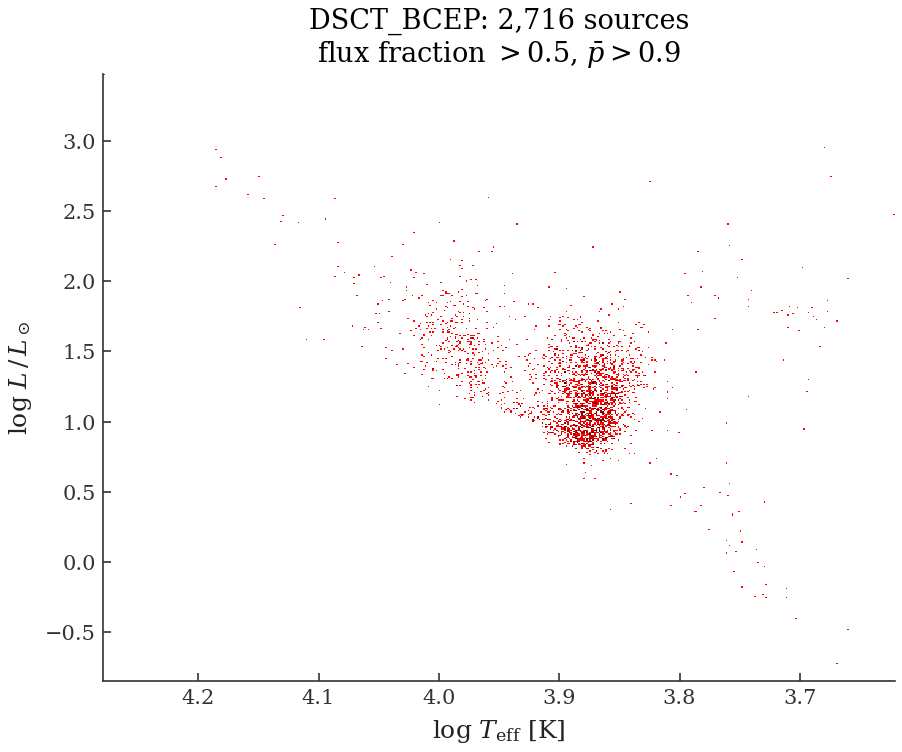

In [83]:
# Filtering by modal class fraction and mean probability

proba_cut = 0.9
cmd_density(df_cmd.filter(
    pl.col('flux_frac').gt(0.5) & pl.col('n_sectors').gt(1) & pl.col('consensus_fraction').gt(proba_cut) & pl.col(f'{sel_class}_mean').gt(proba_cut) 
), title=sel_class, subtitle=r"flux fraction $> 0.5$, $\bar{p} > 0.9$")

# Frequency/Amplitude per source

Text(0.5, 1.0, 'Objects with modal class fraction > 0.75 and average probability > 0.75')

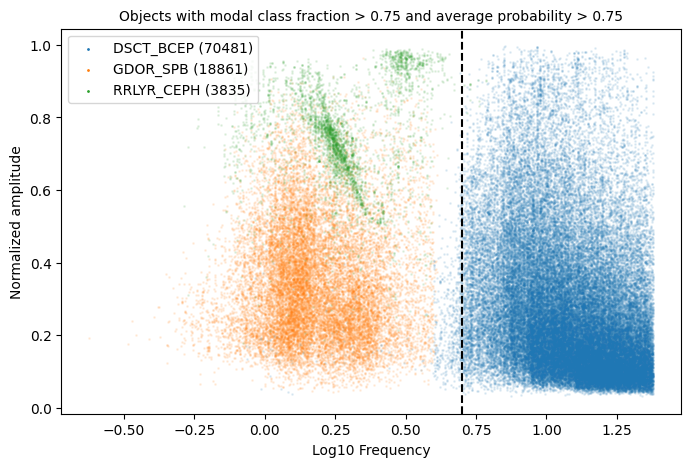

In [299]:
fig = plt.figure(figsize=(8, 5))
ax = fig.add_subplot(111)
for class_name in ['DSCT_BCEP', 'GDOR_SPB', 'RRLYR_CEPH']:
    #fig, ax = plt.subplots(figsize=(6, 4), projection="mollweide")
    freq, ampl = df_gaia_metadata.filter(
        pl.col('mode_class').eq(class_name)
    ).join(median_freqs, on='source_id').select(['ls_frequency_fundamental', 'ls_amplitude_fundamental']).to_numpy().T
    ax.scatter(np.log10(freq), ampl, s=1, alpha=0.1, label=f"{class_name} ({len(freq)})")
    ax.set_xlabel('Log10 Frequency') 
    ax.set_ylabel('Normalized amplitude')
ax.axvline(np.log10(5), ls='--', c='k')
leg = plt.legend()
for lh in leg.legend_handles:
    lh.set_alpha(1)
#ax.set_title(f"{class_name} ({len(freq)})")
ax.set_title('Objects with modal class fraction > 0.75 and average probability > 0.75', fontsize=10)

# Sky coordinates

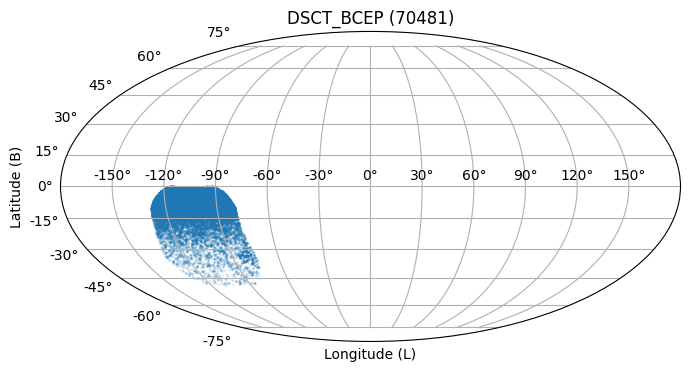

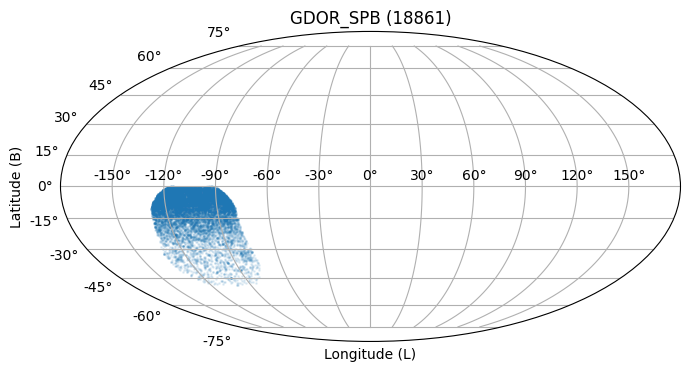

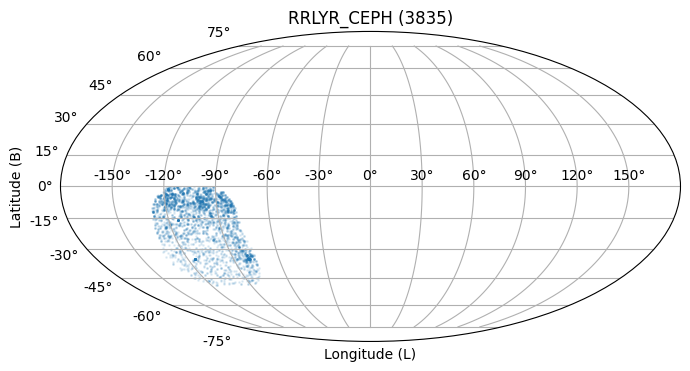

In [293]:
import numpy as np
from astropy.coordinates import SkyCoord
import astropy.units as u

def to_galactic_coord(ra_deg, dec_deg):
    c_icrs = SkyCoord(ra=ra_deg * u.deg, dec=dec_deg * u.deg, frame="icrs")
    c_gal = c_icrs.galactic
    return c_gal.l.to_value(u.rad), c_gal.b.to_value(u.rad)

for class_name in ['DSCT_BCEP', 'GDOR_SPB', 'RRLYR_CEPH']:
    #fig, ax = plt.subplots(figsize=(6, 4), projection="mollweide")
    fig = plt.figure(figsize=(8, 5))
    ax = fig.add_subplot(111, projection="mollweide")
    ra, dec = df_gaia_metadata.filter(
        pl.col('mode_class').eq(class_name) #& pl.col('mode_frac').gt(0.75)
    ).select(['ra', 'dec']).to_numpy().T
    L, B = to_galactic_coord(ra, dec)
    L = (L + np.pi) % (2*np.pi) - np.pi
    ax.scatter(L, B, s=1, alpha=0.1)
    ax.set_xlabel('Longitude (L)') 
    ax.set_ylabel('Latitude (B)')
    ax.grid(True)
    ax.set_title(f"{class_name} ({len(ra)})")

# Export

In [35]:
pl.scan_parquet(
    "/STER/mamsie/tess/TIC/plato_fov/cat_v1_no_path.parquet"
).collect_schema().names()

['GaiaDR3',
 'TIC',
 'RA',
 'DEC',
 'sector',
 'APERIODIC',
 'CONTACT_ROT',
 'DSCT_BCEP',
 'ECLIPSE',
 'GDOR_SPB',
 'INSTRUMENT/JUNK',
 'RRLYR_CEPH',
 'SOLARLIKE',
 'max_prob',
 'class',
 'agree',
 'f1',
 'A1',
 'Teff',
 'Teff_low',
 'Teff_upp',
 'L',
 'L_low',
 'L_upp',
 'Gmag',
 'BP_RP',
 'ncams']

In [37]:
df_all_preds.drop(['path', 'entropy']).rename({
    'ls_frequency_dominant': 'f1',
    'ls_amplitude_dominant': 'A1',
    'pw_frequency_2': 'f2',
    'best_class': 'class',
    'best_proba': 'max_prob',
    'pw_variance_explained_1': 'var_frac_f1',
    'pw_variance_explained_2': 'var_frac_f2'
}).select(
    ['GaiaDR3', 'sector', 'CONTACT_ROT', 'DSCT_BCEP', 'ECLIPSE', 'GDOR_SPB', 'INSTRUMENTAL', 'RRLYR_CEPH', 'SOLARLIKE', 'max_prob', 'class', 'f1', 'A1', 'flux_std', 'f2', 'var_frac_f1', 'var_frac_f2']
).write_parquet('cat_v2.parquet')

In [38]:
source_summary_radec.columns

['GaiaDR3',
 'n_sectors',
 'consensus_class',
 'consensus_fraction',
 'n_unique_classes',
 'CONTACT_ROT_mean',
 'DSCT_BCEP_mean',
 'ECLIPSE_mean',
 'GDOR_SPB_mean',
 'INSTRUMENTAL_mean',
 'RRLYR_CEPH_mean',
 'SOLARLIKE_mean',
 'ls_amplitude_mean',
 'ls_amplitude_std',
 'ls_frequency_mean',
 'ls_frequency_std',
 'TIC',
 'Teff',
 'L',
 'RA',
 'DEC',
 'BP_RP',
 'ncams',
 'Gmag',
 'flux_frac']

In [94]:
source_summary_radec.rename({
    'ls_frequency_mean': 'f1_mean',
    'ls_frequency_std': 'f1_std',
    'ls_amplitude_mean': 'A1_mean',
    'ls_amplitude_std': 'A1_std',
    'flux_frac': 'tglc_flux_fraction'
}).select(
    ['GaiaDR3', 'TIC', 'RA', 'DEC', 'ncams', 'n_sectors',
     'consensus_class', 'consensus_fraction', 'n_unique_classes',
     'CONTACT_ROT_mean', 'DSCT_BCEP_mean', 'ECLIPSE_mean', 'GDOR_SPB_mean', 'INSTRUMENTAL_mean', 'RRLYR_CEPH_mean', 'SOLARLIKE_mean',
     'f1_mean', 'A1_mean', 'f1_std', 'A1_std',
     'Teff', 'L', 'Gmag', 'BP_RP', 'tglc_flux_fraction']
).write_parquet('cat_v2_per_source.parquet')

In [95]:
df_all_preds.shape, source_summary_radec.shape

((36596122, 19), (5987184, 25))

In [47]:
c1, c2 = 'DSCT_BCEP', 'GDOR_SPB'

df_dual_class = pl.scan_parquet('../results/classifications/s*/*.parquet').filter(
    pl.col(c1).gt(0.35) & pl.col(c2).gt(0.35) & pl.col('INSTRUMENT/JUNK').lt(0.05) & pl.col('SOLARLIKE').lt(0.05)  & pl.col('APERIODIC').lt(0.05)
).collect()
df_dual_class

path,APERIODIC,CONTACT_ROT,DSCT_BCEP,ECLIPSE,GDOR_SPB,INSTRUMENT/JUNK,RRLYR_CEPH,SOLARLIKE,best_rf_class,rf_entropy,best_rf_proba
str,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,f64
"""/STER/mamsie/tess/TIC/plato_fo…",0.000345,0.004485,0.538665,0.000804,0.409367,0.042004,0.000532,0.003797,"""DSCT_BCEP""",0.427968,0.538665
"""/STER/mamsie/tess/TIC/plato_fo…",0.016312,0.034099,0.515232,0.003974,0.407216,0.013011,0.0009,0.009256,"""DSCT_BCEP""",0.48954,0.515232
"""/STER/mamsie/tess/TIC/plato_fo…",0.000314,0.057101,0.534757,0.001233,0.401791,0.002521,0.000571,0.001712,"""DSCT_BCEP""",0.435505,0.534757
"""/STER/mamsie/tess/TIC/plato_fo…",0.002271,0.009725,0.609674,0.000502,0.37696,0.000092,0.00012,0.000656,"""DSCT_BCEP""",0.355333,0.609674
"""/STER/mamsie/tess/TIC/plato_fo…",0.001748,0.005948,0.457997,0.002105,0.526725,0.000331,0.000134,0.005012,"""GDOR_SPB""",0.375226,0.526725
…,…,…,…,…,…,…,…,…,…,…,…
"""/STER/mamsie/tess/TIC/plato_fo…",0.000349,0.007284,0.520392,0.000948,0.46978,0.000057,0.000253,0.000937,"""DSCT_BCEP""",0.360304,0.520392
"""/STER/mamsie/tess/TIC/plato_fo…",0.000336,0.036618,0.574988,0.000351,0.383982,0.002237,0.000628,0.00086,"""DSCT_BCEP""",0.402351,0.574988
"""/STER/mamsie/tess/TIC/plato_fo…",0.003802,0.017997,0.5157,0.01104,0.447315,0.000792,0.000622,0.002733,"""DSCT_BCEP""",0.418858,0.5157


In [48]:
ampls = []
freq_interp = (np.linspace(1/27, 24, 5_000))
for row in tqdm(df_dual_class.with_columns(pl.col('path').str.split('-').list.get(2).alias('sourceid')).unique('sourceid').iter_rows(named=True)):
#for row in tqdm(df_dual_class.iter_rows(named=True)):
    path_, proba1, proba2, entropy = row['path'], row[c1], row[c2], row['rf_entropy']
    #sid, sector = path_.split('-')[2:4]
    time, flux, sector = read_fits_lc(path_)
    time_pre, flux_pre = preprocess_lc(time, flux, sector)
    freq, ampl, _ = compute_lombscargle_periodogram(time_pre, flux_pre)
    ampls.append(np.interp(freq_interp, (freq), ampl))
ampls = np.stack(ampls)

0it [00:00, ?it/s]

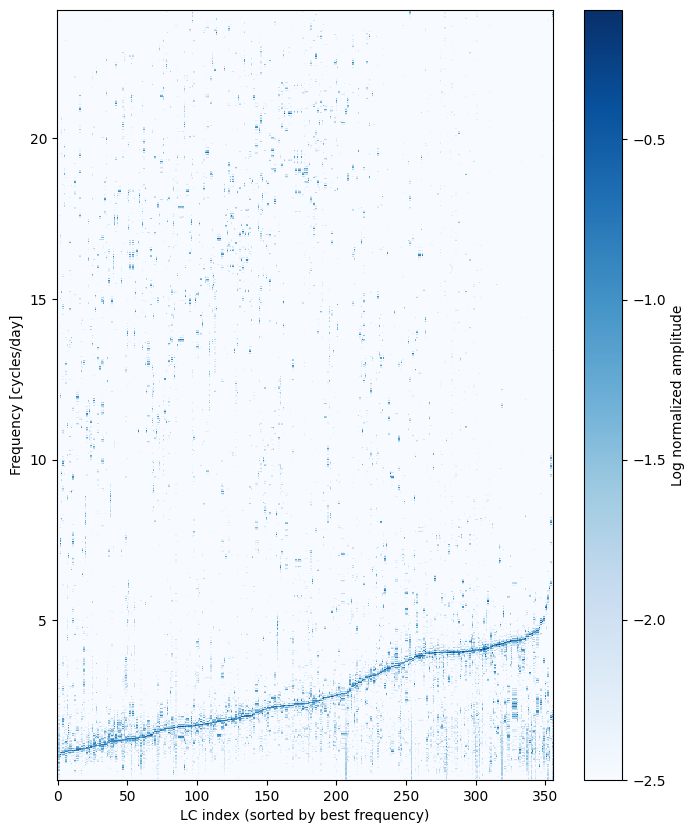

In [50]:
best_freq_loc = np.argmax(ampls, axis=1)
fig, ax = plt.subplots(figsize=(8, 10))
im = ax.pcolormesh(range(len(ampls)), freq_interp, np.log10(ampls[np.argsort(best_freq_loc)].T), cmap=plt.cm.Blues, vmin=-2.5)
ax.set_ylabel('Frequency [cycles/day]')
ax.set_xlabel('LC index (sorted by best frequency)')
plt.colorbar(im, label='Log normalized amplitude')

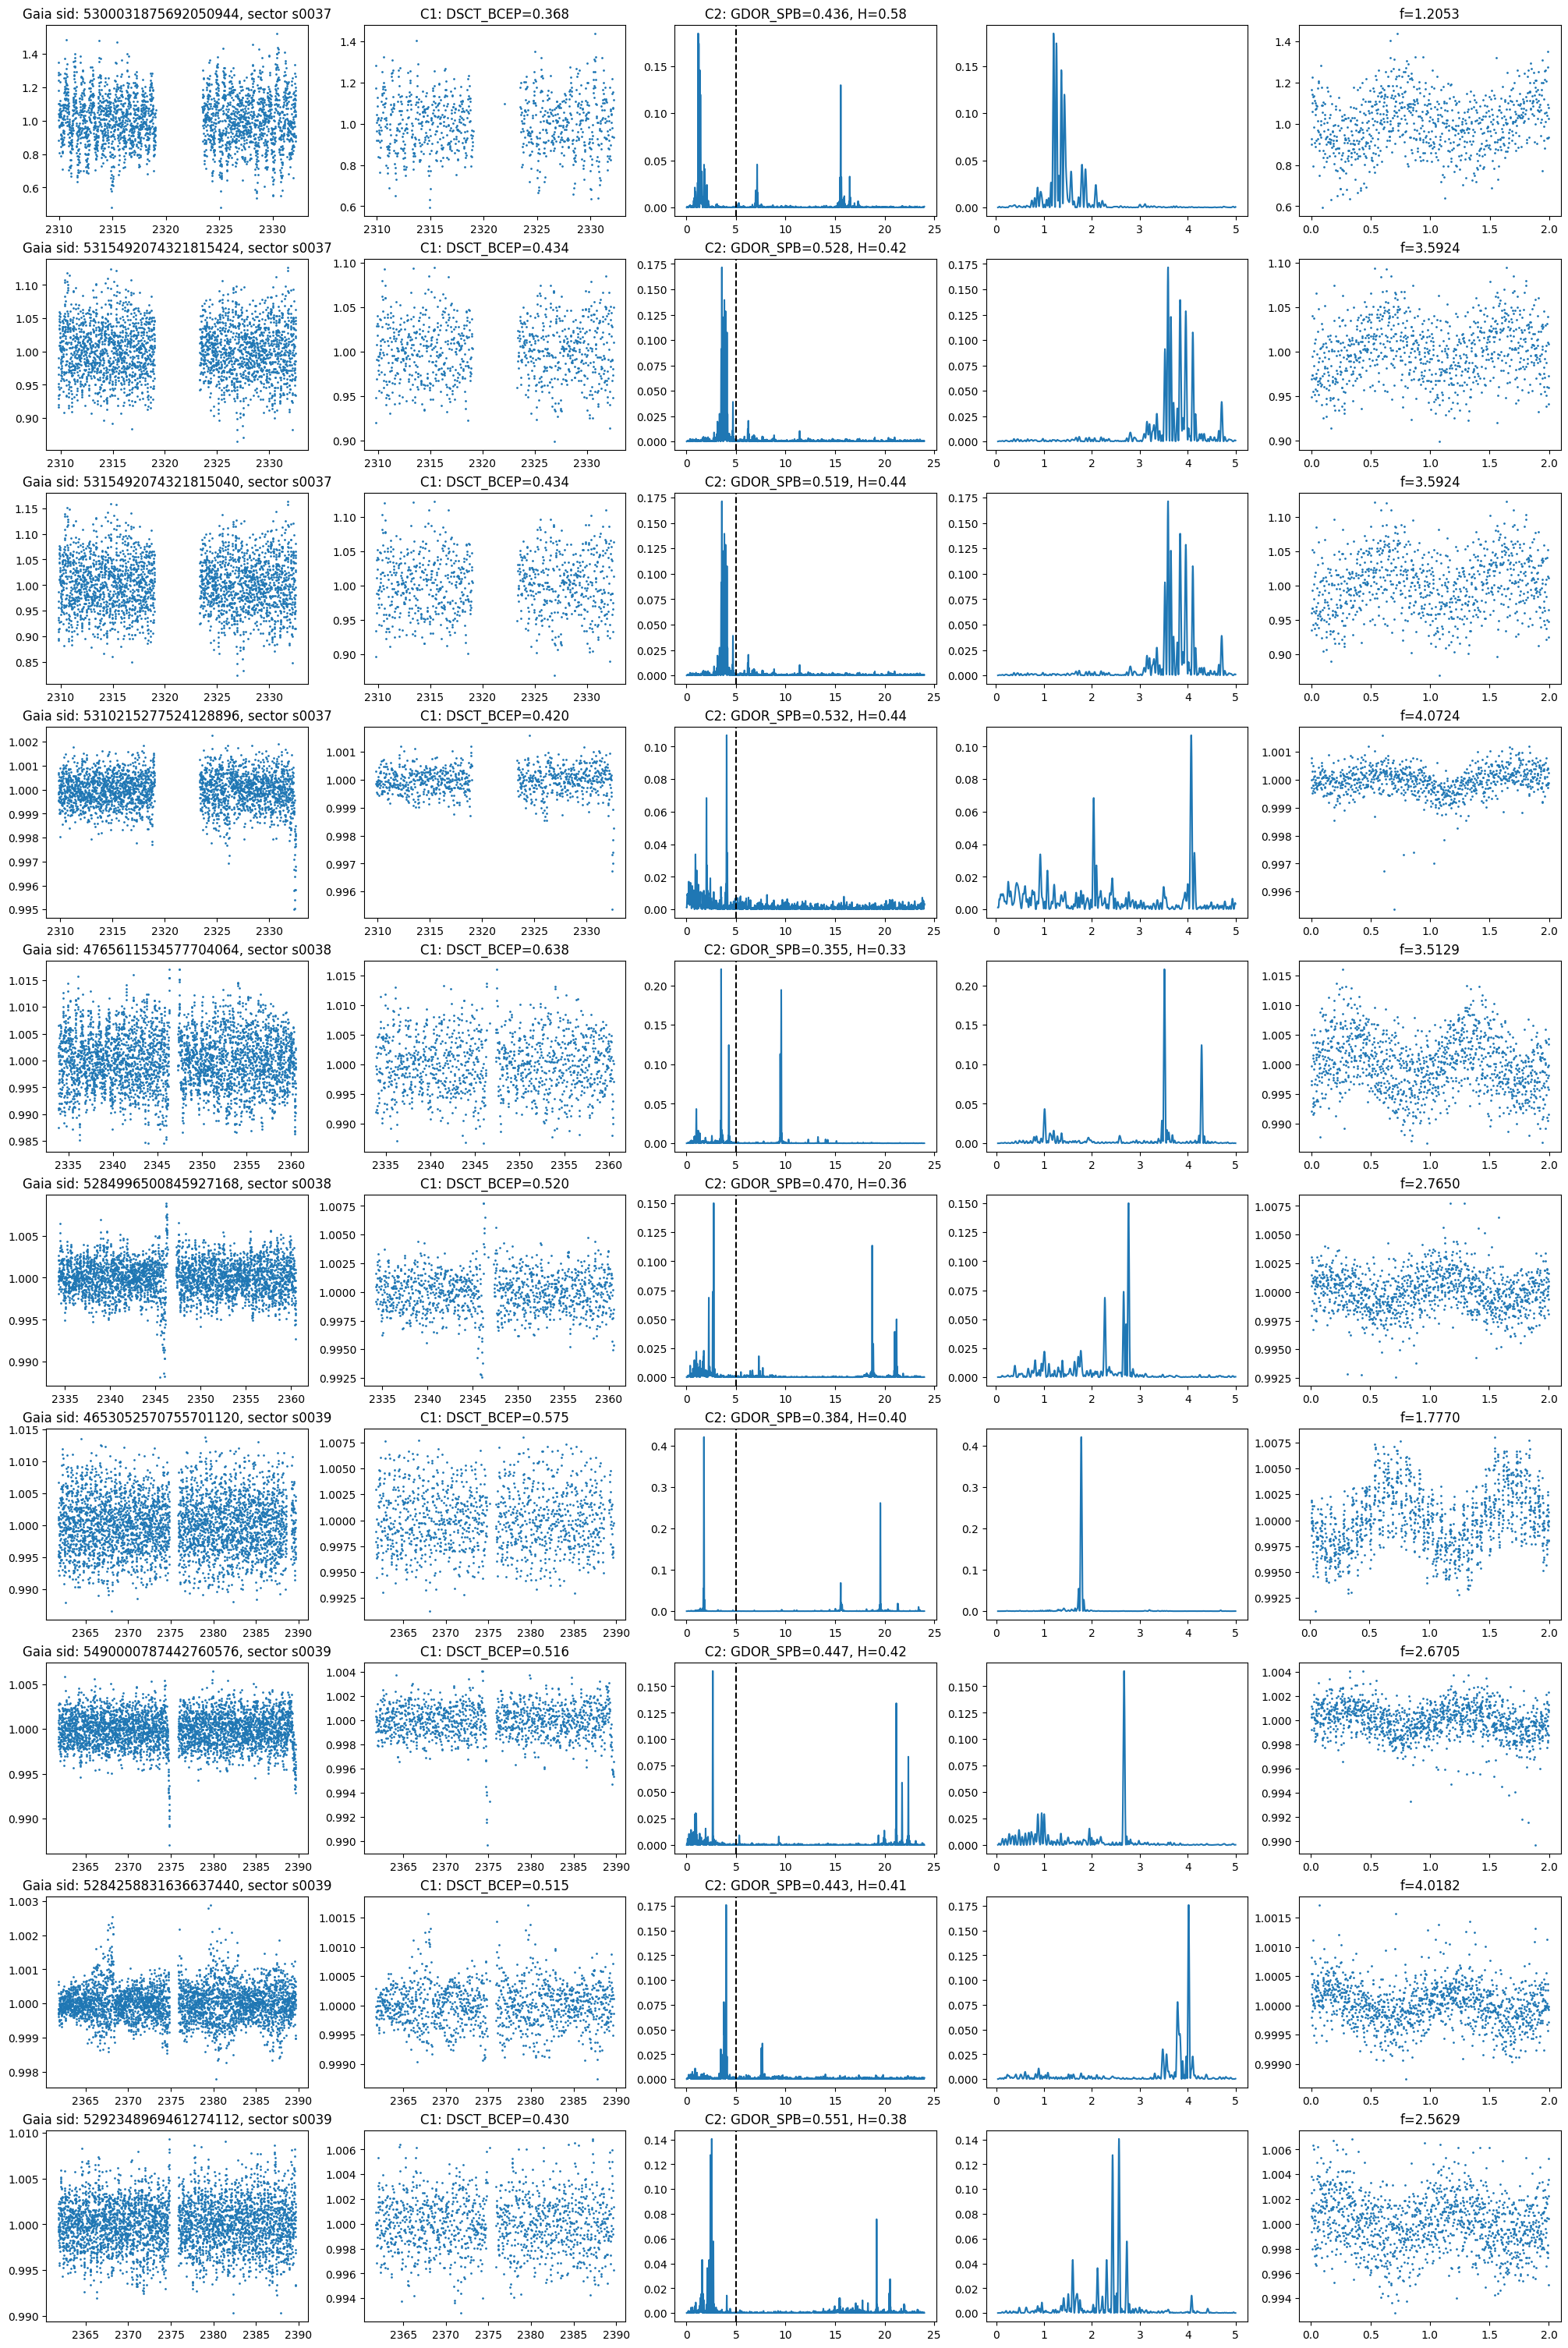

In [51]:
n_plots = min(10, df_dual_class.height)
fig, axs = plt.subplots(max(2, n_plots), 5, figsize=(20, 3*n_plots), constrained_layout=True, sharex=False)
for row, ax in zip(df_dual_class.tail(10).iter_rows(named=True), axs):
    path_, proba1, proba2, entropy = row['path'], row[c1], row[c2], row['rf_entropy']
    sid, sector = path_.split('-')[2:4]
    ax[0].set_title(f"Gaia sid: {sid}, sector {sector}")
    ax[1].set_title(f"C1: {c1}={proba1:0.3f}")
    ax[2].set_title(f"C2: {c2}={proba2:0.3f}, H={entropy:0.2f}")
    time, flux, sector = read_fits_lc(path_)
    ax[0].scatter(time, flux, s=1)
    time_pre, flux_pre = preprocess_lc(time, flux, sector)
    ax[1].scatter(time_pre, flux_pre, s=1)
    freq, ampl, _ = compute_lombscargle_periodogram(time_pre, flux_pre)
    best_freq = freq[np.argmax(ampl)]
    ax[2].plot(freq, ampl)
    ax[2].axvline(5, ls='--', c='k')
    ax[3].plot(freq[freq<5], ampl[freq<5])
    ax[4].set_title(f"f={best_freq:0.4f}")
    ax[4].scatter(np.mod(time_pre, 2/best_freq)*best_freq, flux_pre, s=1)

## Conny's sources



In [89]:
connys_list = [4757524489124658048, 5495052596695570816, 5486695861648434304, 5486981524216356608, 4793601557272771968, 4794632903476180096, 4799007688445126016, 4805806449875760384, 5497072086021346688]

In [90]:
source_summary.filter(pl.col('source_id').is_in(connys_list))

source_id,n_lc,n_unique_classes,mode_class,mode_count,mode_frac,label_entropy,label_entropy_norm,proba_mean,entropy_mean
i64,u32,u32,str,u32,f64,f64,f64,f64,f64
5486695861648434304,14,3,"""APERIODIC""",6,0.428571,1.004242,0.482939,0.607894,0.505546
4799007688445126016,5,3,"""APERIODIC""",2,0.4,1.05492,0.507309,0.56733,0.541074
4794632903476180096,5,2,"""APERIODIC""",3,0.6,0.673012,0.32365,0.5745,0.497031
5497072086021346688,24,5,"""APERIODIC""",10,0.416667,1.362275,0.655116,0.631364,0.497442
4793601557272771968,7,3,"""APERIODIC""",5,0.714286,0.796312,0.382945,0.730328,0.401655
4805806449875760384,2,1,"""APERIODIC""",2,1.0,-0.0,-0.0,0.922561,0.17327
5486981524216356608,10,2,"""SOLARLIKE""",7,0.7,0.610864,0.293764,0.530941,0.573223
5495052596695570816,23,2,"""CONTACT_ROT""",20,0.869565,0.387212,0.18621,0.847815,0.213602
4757524489124658048,23,4,"""APERIODIC""",12,0.521739,1.187775,0.571199,0.608846,0.537118


path,best_rf_class,best_rf_proba,rf_entropy,ls_frequency_fundamental,ls_amplitude_fundamental,num_negative_fluxes,source_id
str,str,f64,f64,f64,f64,i64,i64
"""/STER/mamsie/tess/TIC/plato_fo…","""INSTRUMENT/JUNK""",0.669197,0.58274,2.798773,0.012214,0,4757524489124658048
"""/STER/mamsie/tess/TIC/plato_fo…","""APERIODIC""",0.713185,0.473403,1.172156,0.036762,0,4757524489124658048
"""/STER/mamsie/tess/TIC/plato_fo…","""GDOR_SPB""",0.744256,0.485726,1.529983,0.040051,0,4757524489124658048
"""/STER/mamsie/tess/TIC/plato_fo…","""SOLARLIKE""",0.420268,0.749386,1.112608,0.053853,0,4757524489124658048
"""/STER/mamsie/tess/TIC/plato_fo…","""APERIODIC""",0.703989,0.512535,0.693429,0.030152,0,4757524489124658048
…,…,…,…,…,…,…,…
"""/STER/mamsie/tess/TIC/plato_fo…","""SOLARLIKE""",0.3258,0.802859,1.728342,0.029309,0,4757524489124658048
"""/STER/mamsie/tess/TIC/plato_fo…","""APERIODIC""",0.528027,0.629861,0.750254,0.077705,0,4757524489124658048
"""/STER/mamsie/tess/TIC/plato_fo…","""GDOR_SPB""",0.648254,0.524153,1.223194,0.057255,0,4757524489124658048


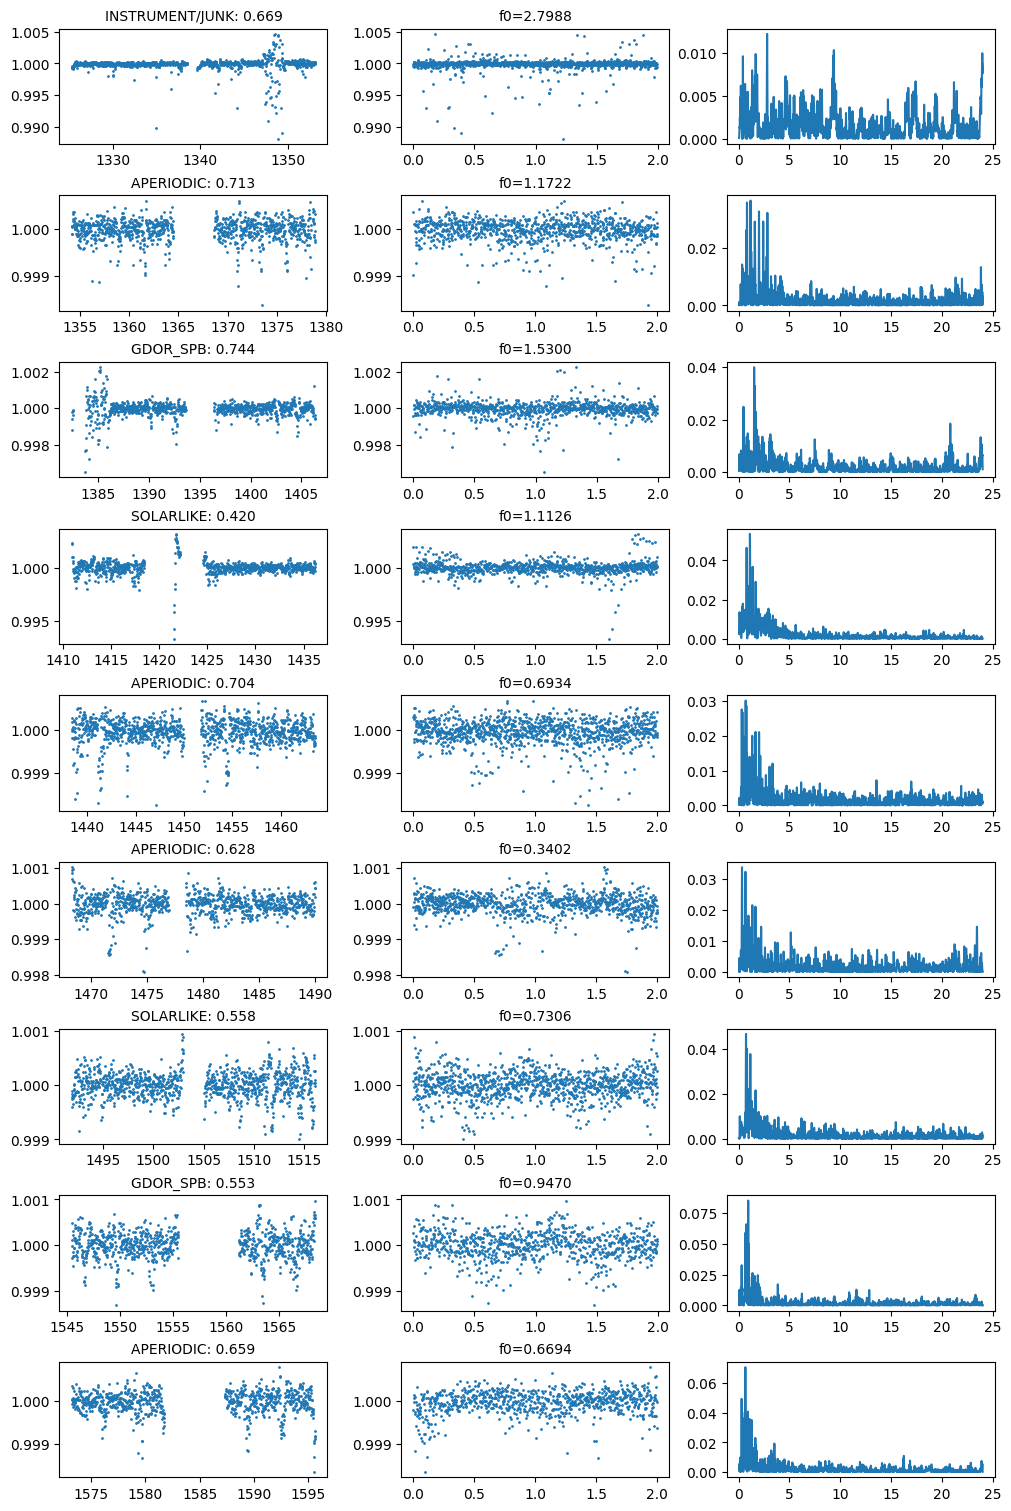

In [93]:
fig, axs = plt.subplots(9, 3, figsize=(10, 15), constrained_layout=True)
for row, ax in zip(df_all_preds.filter(pl.col('source_id').eq(4757524489124658048)).iter_rows(named=True), axs):
    path_, freq_ = row['path'], row['ls_frequency_fundamental']
    #time, flux, sector = read_fits_lc(path_, flux_column='cal_psf_flux')
    time, flux, sector = read_fits_lc(path_)
    time, flux = preprocess_lc(time,flux,sector)
    ax[0].scatter(time, flux, s=1)
    ax[0].set_title(f'{row["best_rf_class"]}: {row["best_rf_proba"]:0.3f}', fontsize=10)
    phase = np.mod(time, 2./freq_)*freq_
    ax[1].scatter(phase, flux, s=1)
    ax[1].set_title(f'f0={freq_:0.4f}', fontsize=10)
    freq, ampl, _ = compute_lombscargle_periodogram(time, flux)
    ax[2].plot(freq, ampl)
    #ax[0].set_ylabel(row['sector'])